# Weinreb metaclone ancestry worked examples

## Goal
Use an observed temporal clonal phenotype to define a retrospective comparison
of Day-2 HSPCs. The monocyte example compares related lineage output with
different developmental positions; the multilineage example compares changing
branch occupancy. A positive molecular result is not a prerequisite for using
the workflow. Day-2 cells are sampled clonal relatives, not directly observed
ancestors of the later sequenced cells.

This companion preserves the original fixed 50-Hallmark universe and original
multiple-testing families. It reconstructs and verifies the source scores and
contrasts before adding a declared 50-program fast-minus-slow monocyte contrast.
All inference is one observation per LARRY clone. Every result and takeaway
below is generated by executed code; no biological conclusion is hard-coded.

## Setup and environment
Reuse environment **chronoclone**, installed locally at
`/path/to/ChronoClone/.runtime/chronoclone`, Jupyter kernel
`chronoclone`. The existing Conda-compatible environment is reused without
installation or mutation. Runtime versions and the exact command are printed
in the first code cell. The original complete analysis is
`../weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb`.

### Interpretation contract
- Metaclones and behavior comparisons were chosen from the observed atlas;
  this is post-selection ancestry characterization, not independent validation.
- Show every effect. Original q < 0.05 and exploratory 0.05 <= q < 0.10
  are distinct display tiers; the full tested families remain fixed.
- A pooled pace contrast is not a shared program or proof that each MC has
  the same molecular mechanism. Individual-MC results retain peer checks.
- Library influence and starting-state composition are assessed explicitly.
  Unsupported source-restricted comparisons are not treated as negative.
- Gene contribution plots decompose the same program contrast. They add no
  gene-level significance test or causal claim.
- Each plot has one cell and one editable SVG stem. No Singh analysis is run.

In [1]:
import os, sys, json, hashlib, shutil, warnings, itertools, re
from pathlib import Path
import importlib.metadata as im
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
import statsmodels.api as sm
import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display
import nbformat

PROJECT_ROOT = Path('/path/to/ChronoClone')
ANALYSIS_DIR = PROJECT_ROOT / 'analysis_workspace/analyses/weinreb_metaclone_ancestry_worked_examples_20260910'
SOURCE_DIR = PROJECT_ROOT / 'analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902'
FIGDIR, TABLEDIR, REPORTDIR = [ANALYSIS_DIR / name for name in ['figures','tables','reports']]
PROVDIR = ANALYSIS_DIR / 'provenance'
for directory in [FIGDIR,TABLEDIR,REPORTDIR,PROVDIR]: directory.mkdir(parents=True,exist_ok=True)
NOTEBOOK_PATH = ANALYSIS_DIR / '0001_weinreb_metaclone_ancestry_worked_examples.ipynb'
ENV_PATH = Path('/path/to/ChronoClone/.runtime/chronoclone')
EXECUTION_COMMAND = f'env OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 MPLCONFIGDIR=/private/tmp/weinreb_ancestry_mpl NUMBA_CACHE_DIR=/private/tmp/weinreb_ancestry_numba {ENV_PATH}/bin/jupyter-nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone --ExecutePreprocessor.timeout=7200 {NOTEBOOK_PATH}'
assert Path(sys.executable).resolve() == (ENV_PATH/'bin/python').resolve()
environment = pd.DataFrame({'field':['environment_name','manager','path','kernel','python','execution_command'] + ['version_'+p for p in ['numpy','pandas','scipy','statsmodels','anndata','matplotlib','nbformat','pydeseq2']],
 'value':['chronoclone','Existing Conda-compatible environment; reused without mutation',str(ENV_PATH),'chronoclone',sys.version.split()[0],EXECUTION_COMMAND] + [im.version(p) for p in ['numpy','pandas','scipy','statsmodels','anndata','matplotlib','nbformat','pydeseq2']]})
environment.to_csv(REPORTDIR/'environment.csv',index=False)
display(environment)
from matplotlib import font_manager
PLOT_FONT='DejaVu Sans'
plot_font_path=font_manager.findfont(PLOT_FONT,fallback_to_default=False)
assert Path(plot_font_path).exists()
print('Verified plotting font:',PLOT_FONT,plot_font_path)
mpl.rcParams.update({'svg.fonttype':'none','font.family':PLOT_FONT,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'savefig.facecolor':'white','figure.facecolor':'white'})
BLUE,RED,GREY = '#2166AC','#B2182B','#708090'
PROGRAM_CMAP = LinearSegmentedColormap.from_list('negative_blue_zero_white_positive_red',[BLUE,'#FFFFFF',RED],N=257)
PROGRAM_CMAP.set_bad('#D9DEE5')
# Generic audit instrumentation only; all plot calculation/construction stays inline.
figure_creation_log=[]; svg_save_log=[]; plot_runtime_audit=[]
original_figure_factory=plt.figure
original_savefig=mpl.figure.Figure.savefig
def audited_figure_factory(*args,**kwargs):
    figure=original_figure_factory(*args,**kwargs)
    figure_creation_log.append(id(figure))
    return figure
def audited_savefig(figure,path,*args,**kwargs):
    if str(path).lower().endswith('.svg'): svg_save_log.append(str(path))
    return original_savefig(figure,path,*args,**kwargs)
plt.figure=audited_figure_factory
mpl.figure.Figure.savefig=audited_savefig
MONO_ORDER = [6,8,7,12]
MULTI_ORDER = [0,2,5,3,18,4,11]
FAMILY_GROUPS = {'Neutrophil':[9,14,16,22,1],'Monocyte':[12,7,8,6],'Erythroid / Mk':[10,17,23],'Basophil':[13],'Multi-lineage':MULTI_ORDER}
MC_TO_FAMILY = {mc:f for f,ms in FAMILY_GROUPS.items() for mc in ms}
MC_ORDER = list(MC_TO_FAMILY)
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()
def safe_name(s): return re.sub(r'[^A-Za-z0-9]+','_',str(s)).strip('_')
def clean_program_name(s): return str(s).replace('HALLMARK_','').replace('_',' ').title()
def bh_adjust(values):
    a=np.asarray(values,float); out=np.full(len(a),np.nan); good=np.flatnonzero(np.isfinite(a))
    if len(good):
        order=good[np.argsort(a[good],kind='stable')]
        q=np.minimum.accumulate((a[order]*len(order)/np.arange(1,len(order)+1))[::-1])[::-1]
        out[order]=np.clip(q,0,1)
    return out
def evidence_tier(q,supported=True):
    if not supported or not np.isfinite(q): return 'not_estimable_or_unsupported'
    return 'FDR_lt_0.05' if q<.05 else 'exploratory_0.05_to_0.10' if q<.10 else 'displayed_without_FDR_support'

# Preserve dated manuscript inputs before any integration, never overwrite.
snapshot_dir=PROVDIR/'prior_manuscript_20260910'; snapshot_dir.mkdir(exist_ok=True)
manuscript_dir=PROJECT_ROOT/'analysis_workspace/manuscript_drafts/chronoclone_weinreb_manuscript_20260901'
snapshot_records=[]
for name in ['manuscript.md','build_cell_reports_docx.py','chronoclone_cell_reports_publication_panels_20260907.docx']:
    src=manuscript_dir/name; dest=snapshot_dir/name
    if src.exists() and not dest.exists(): shutil.copy2(src,dest)
    if dest.exists(): snapshot_records.append({'original_path':str(src.relative_to(PROJECT_ROOT)),'snapshot_path':str(dest.relative_to(PROJECT_ROOT)),'sha256':sha256(dest),'bytes':dest.stat().st_size})
pd.DataFrame(snapshot_records).to_csv(PROVDIR/'manuscript_snapshot_register.csv',index=False)
display(pd.DataFrame(snapshot_records))

,field,value
0,environment_name,chronoclone
1,manager,Existing Conda-compatible environment; reused ...
2,path,~/.reference-science/conda/envs/...
3,kernel,chronoclone
4,python,3.11.15
5,execution_command,env OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 M...
6,version_numpy,2.4.6
7,version_pandas,2.3.3
8,version_scipy,1.17.1
9,version_statsmodels,0.14.6


Verified plotting font: DejaVu Sans /path/to/ChronoClone/.runtime/chronoclone/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf


,original_path,snapshot_path,sha256,bytes
0,analysis_workspace/manuscript_drafts/chronoclone_we...,analysis_workspace/analyses/weinreb_metaclone_ances...,bc6a8c13b5e7424db4d52c67e9451935ac85b4db7fbf68...,70691
1,analysis_workspace/manuscript_drafts/chronoclone_we...,analysis_workspace/analyses/weinreb_metaclone_ances...,ec7120ec2df3d09f58c48f9893c0566b2260bf5a3b7a65...,10217
2,analysis_workspace/manuscript_drafts/chronoclone_we...,analysis_workspace/analyses/weinreb_metaclone_ances...,49d80ff296ff045ea80af7a2fedf8db074eb69968fb81a...,11368697


## 1. Load the frozen ancestry groups and source measurements
The complete Day-2 discovery cohort and the currently assigned ancestry cohort
are recorded separately. The same LARRY barcode identifies the contributing
Day-2 and later snapshots. The frozen original score and contrast tables are
read-only sources; all new outputs go into this companion directory.

In [2]:
INPUT_H5AD=PROJECT_ROOT/'reference_workspace/data/klein_metaclone_palantir_trajectories.h5ad'
LINEAGE_MAP=PROJECT_ROOT/'reference_workspace/Figure/fig2/data/fig2h_lineage_bias_map.csv'
assert sha256(INPUT_H5AD)=='4cb08c12dc70f5c3789a75a09a6399db06b3f6efe18147b9f2cca0908ba93911'
assert sha256(LINEAGE_MAP)=='b4d1af7b481a9b1a26d781feb449fb88d300d770c20633054e152f213fa18eb6'
source_files=[INPUT_H5AD,LINEAGE_MAP] + [SOURCE_DIR/'tables'/n for n in ['group_blind_gene_filter.csv','hallmark_gene_mapping_audit.csv','day2_hspc_clone_pseudobulk_metadata.csv','clone_hallmark_program_scores.csv.gz','hallmark_program_contrasts.csv','contrast_registry.csv','adjusted_program_means_by_metaclone.csv','cnmf_postfreeze_program_recovery_summary.csv','cnmf_metaclone_program_novelty_assessment.csv']]
source_manifest=pd.DataFrame([{'path':str(p.relative_to(PROJECT_ROOT)),'bytes':p.stat().st_size,'sha256':sha256(p)} for p in source_files])
source_manifest.to_csv(PROVDIR/'source_manifest.csv',index=False)
A=ad.read_h5ad(INPUT_H5AD)
A.obs=A.obs.drop(columns=['population'],errors='ignore')
obs=A.obs.copy()
obs['metaclone']=pd.to_numeric(obs.metaclone,errors='coerce')
obs['day']=pd.to_numeric(obs.day,errors='coerce')
for col in ['LARRY_ID','Library','cell_type']: obs[col]=obs[col].astype(str)
assert 'population' not in obs.columns
all_day2=obs[(obs.day==2)&obs.cell_type.isin(['prog_1','prog_2'])].copy()
hspc_cells=all_day2[all_day2.metaclone.isin(MC_ORDER)].copy()
hspc_cells['metaclone']=hspc_cells.metaclone.astype(int)
assert hspc_cells.groupby('LARRY_ID').metaclone.nunique().max()==1
lineage_map=pd.read_csv(LINEAGE_MAP)
assert lineage_map.set_index('metaclone').family.to_dict()==MC_TO_FAMILY
old_scores=pd.read_csv(SOURCE_DIR/'tables/clone_hallmark_program_scores.csv.gz',index_col=0)
old_scores.index=old_scores.index.astype(str)
program_names=set(pd.read_csv(SOURCE_DIR/'tables/hallmark_gene_mapping_audit.csv').program)
PROGRAMS=[c for c in old_scores if c in program_names]
assert len(PROGRAMS)==50
old_tests=pd.read_csv(SOURCE_DIR/'tables/hallmark_program_contrasts.csv')
old_specs=pd.read_csv(SOURCE_DIR/'tables/contrast_registry.csv')
mapping=pd.read_csv(SOURCE_DIR/'tables/hallmark_gene_mapping_audit.csv').set_index('program').loc[PROGRAMS]
gene_filter=pd.read_csv(SOURCE_DIR/'tables/group_blind_gene_filter.csv')
GENES=gene_filter.loc[gene_filter.retained.astype(bool),'gene'].tolist()
POS=pd.Series(np.arange(A.n_obs),index=A.obs_names)
gene_positions=A.var_names.get_indexer(GENES); assert (gene_positions>=0).all()
gene_lookup={g:i for i,g in enumerate(GENES)}
program_gene_indices={p:np.array([gene_lookup[g] for g in mapping.loc[p,'mapped_genes'].split('|')]) for p in PROGRAMS}
libraries=sorted(hspc_cells.Library.unique())
cohort_summary=pd.DataFrame({'cohort':['All Day2 prog_1+prog_2','Assigned ancestry cohort','Monocyte example','Multilineage example'],
 'cells':[len(all_day2),len(hspc_cells),hspc_cells.metaclone.isin(MONO_ORDER).sum(),hspc_cells.metaclone.isin(MULTI_ORDER).sum()],
 'clones':[all_day2.LARRY_ID.nunique(),hspc_cells.LARRY_ID.nunique(),hspc_cells.loc[hspc_cells.metaclone.isin(MONO_ORDER),'LARRY_ID'].nunique(),hspc_cells.loc[hspc_cells.metaclone.isin(MULTI_ORDER),'LARRY_ID'].nunique()]})
cohort_summary.to_csv(TABLEDIR/'cohort_summary.csv',index=False)
display(cohort_summary)

,cohort,cells,clones
0,All Day2 prog_1+prog_2,1041,784
1,Assigned ancestry cohort,775,569
2,Monocyte example,184,135
3,Multilineage example,290,217


## 2. Reconstruct one molecular measurement per clone
The source has no native count layer. We use the retained minimum-positive-value
integer recovery assumption, verify its lattice error, and sum recovered counts
within clone. The original gene universe, Hallmark membership, ratio normalization,
and score standardization are reproduced exactly. This is a compatibility check,
not proof that the inferred integer matrix equals unavailable original UMIs.

In [3]:
expression=A.X.tocsr().copy() if sp.issparse(A.X) else sp.csr_matrix(A.X)
expression.data=np.expm1(expression.data)
nnz=np.diff(expression.indptr); assert (nnz>0).all()
row_min=np.minimum.reduceat(expression.data,expression.indptr[:-1])
lattice=expression.data/np.repeat(row_min,nnz)
count_error=float(np.max(np.abs(lattice-np.rint(lattice))))
assert count_error<1e-6
COUNTS=expression.copy(); COUNTS.data=np.rint(lattice).astype(np.int64)
COUNTS=COUNTS[:,gene_positions].tocsr()
del expression,lattice

def aggregate_cells(cells):
    count_rows=[]; records=[]
    for clone,frame in cells.groupby('LARRY_ID',observed=True,sort=True):
        count_rows.append(np.asarray(COUNTS[POS.loc[frame.index]].sum(axis=0)).ravel())
        rec={'sample':str(clone),'clone':str(clone),'metaclone':int(frame.metaclone.iloc[0]),'n_cells':len(frame),
             'n_prog_1_cells':int((frame.cell_type=='prog_1').sum()),'n_prog_2_cells':int((frame.cell_type=='prog_2').sum())}
        rec['lineage_bias']=MC_TO_FAMILY[rec['metaclone']]
        for lib in libraries: rec['libfrac__'+safe_name(lib)]=float((frame.Library==lib).mean())
        records.append(rec)
    meta=pd.DataFrame(records).set_index('sample')
    return pd.DataFrame(count_rows,index=meta.index,columns=GENES),meta

def score_counts(counts,reference=None,normalization='ratio'):
    values=counts.to_numpy(float)
    api_max_error=np.nan
    with np.errstate(divide='ignore'): logcounts=np.log(values)
    logmeans=np.mean(logcounts,axis=0)
    valid=np.isfinite(logmeans)
    if normalization=='ratio':
        assert valid.sum()>0,'Ratio normalization has no universally positive genes; investigate before changing normalization'
        sf=np.exp(np.median(logcounts[:,valid]-logmeans[valid],axis=1))
    elif normalization=='nonmito_poscounts':
        # Declared after auditing the original denominator, before inspecting
        # this sensitivity's effects. Retain all fixed genes for program scoring.
        from pydeseq2.dds import DeseqDataSet
        from pydeseq2.default_inference import DefaultInference
        controls=np.array([not g.lower().startswith('mt-') for g in GENES])
        dds=DeseqDataSet(counts=counts.astype(int),metadata=pd.DataFrame(index=counts.index),design='~1',inference=DefaultInference(n_cpus=1),quiet=True,refit_cooks=False)
        dds.fit_size_factors(fit_type='poscounts',control_genes=controls)
        sf=dds.obs['size_factors'].to_numpy(float)
        # Independently verify installed PyDESeq2's positive-count algorithm.
        positive_logs=np.zeros_like(values)
        np.log(values,out=positive_logs,where=values>0)
        positive_logmeans=positive_logs.mean(axis=0)
        valid=controls & (positive_logmeans>0)
        expected=np.array([np.exp(np.median(np.log(v[valid & (v>0)])-positive_logmeans[valid & (v>0)])) for v in values])
        expected/=np.exp(np.mean(np.log(expected)))
        api_max_error=float(np.max(np.abs(sf-expected)))
        assert np.allclose(sf,expected,atol=1e-12,rtol=1e-12)
    else: raise ValueError(normalization)
    print('Normalization:',normalization,'eligible genes:',int(valid.sum()),'of',len(GENES))
    lognorm=np.log2(values/sf[:,None]+1)
    mu=lognorm.mean(axis=0); sd=lognorm.std(axis=0,ddof=1)
    z=np.divide(lognorm-mu,sd,out=np.zeros_like(lognorm),where=sd>1e-12)
    raw=np.column_stack([z[:,program_gene_indices[p]].mean(axis=1) for p in PROGRAMS])
    p_mu=raw.mean(axis=0); p_sd=raw.std(axis=0,ddof=1)
    scores=(raw-p_mu)/p_sd
    result={'scores':pd.DataFrame(scores,index=counts.index,columns=PROGRAMS),'gene_z':z,'lognorm':lognorm,'gene_mean':mu,'gene_sd':sd,'program_raw_mean':p_mu,'program_raw_sd':p_sd,'size_factors':sf,'normalization_genes':int(valid.sum()),'normalization_gene_names':'|'.join(np.asarray(GENES)[valid]),'normalization_method':normalization,'normalization_genes_per_clone':((values>0)&valid).sum(axis=1)}
    result['size_factor_api_max_error']=api_max_error
    if reference is not None:
        # Same primary gene/program scaling, after each refit's ratio normalization.
        rz=np.divide(lognorm-reference['gene_mean'],reference['gene_sd'],out=np.zeros_like(lognorm),where=reference['gene_sd']>1e-12)
        rr=np.column_stack([rz[:,program_gene_indices[p]].mean(axis=1) for p in PROGRAMS])
        result['fixed_scale_scores']=pd.DataFrame((rr-reference['program_raw_mean'])/reference['program_raw_sd'],index=counts.index,columns=PROGRAMS)
    return result

counts,metadata=aggregate_cells(hspc_cells)
baseline=score_counts(counts)
program_scores=baseline['scores']
score_error=float(np.max(np.abs(program_scores.loc[old_scores.index,PROGRAMS].to_numpy()-old_scores[PROGRAMS].to_numpy())))
assert score_error<1e-8,score_error
metadata.to_csv(TABLEDIR/'clone_metadata.csv')
metadata.join(program_scores).to_csv(TABLEDIR/'clone_program_scores.csv.gz',compression='gzip')
score_audit=pd.DataFrame({'check':['integer_lattice_error','reconstructed_score_max_error','normalization_genes','fixed_filtered_genes','fixed_programs'], 'value':[count_error,score_error,baseline['normalization_genes'],len(GENES),len(PROGRAMS)]})
score_audit.to_csv(REPORTDIR/'score_reconstruction_audit.csv',index=False)
display(score_audit)

Normalization: ratio eligible genes: 9 of 9777


,check,value
0,integer_lattice_error,4.547474e-13
1,reconstructed_score_max_error,3.108624e-15
2,normalization_genes,9.000000e+00
3,fixed_filtered_genes,9.777000e+03
4,fixed_programs,5.000000e+01


## 3. Preserve the original contrasts and add one declared pace comparison
Library-adjusted OLS uses HC3 uncertainty at clone level. Original within-family
OVR and pairwise q values retain their full 950- and 2,000-test families,
including the original unsupported rows. The new equal-metaclone-weighted
(MC7+MC12)/2 minus (MC6+MC8)/2 contrast uses a separate 50-Hallmark BH family.
Confidence intervals are pointwise 95% intervals, not simultaneous intervals.

In [4]:
def build_design(meta,source_adjust=False):
    group_counts=meta.metaclone.value_counts()
    fit_meta=meta[meta.metaclone.isin(group_counts[group_counts>=3].index)].copy()
    groups=[mc for mc in MC_ORDER if mc in fit_meta.metaclone.unique()]
    design=pd.DataFrame({f'MC{mc}':(fit_meta.metaclone==mc).astype(float) for mc in groups},index=fit_meta.index)
    frac=[c for c in fit_meta if c.startswith('libfrac__')]
    ref=max(frac,key=lambda c:((fit_meta.groupby('metaclone')[c].mean()>0).sum(),fit_meta[c].mean()))
    kept=[]; dropped=[]
    for c in frac:
        if c==ref or fit_meta[c].std(ddof=0)<=1e-12: continue
        z=(fit_meta[c]-fit_meta[c].mean())/fit_meta[c].std(ddof=0)
        trial=np.column_stack([design.to_numpy(),z])
        if np.linalg.matrix_rank(trial)>np.linalg.matrix_rank(design): design[c]=z; kept.append(c)
        else: dropped.append(c)
    source_ok=True
    if source_adjust:
        fraction=fit_meta.n_prog_2_cells/fit_meta.n_cells
        if fraction.std(ddof=0)<1e-12: source_ok=False
        else:
            z=(fraction-fraction.mean())/fraction.std(ddof=0)
            trial=np.column_stack([design.to_numpy(),z])
            source_ok=np.linalg.matrix_rank(trial)>np.linalg.matrix_rank(design)
            if source_ok: design['prog2_fraction_z']=z; kept.append('prog2_fraction_z')
    audit={'n_fit_clones':len(fit_meta),'n_fit_metaclones':len(groups),'reference_library_fraction':ref,'covariates':'|'.join(kept),'rank_dropped':'|'.join(dropped),'rank':np.linalg.matrix_rank(design),'condition_number':np.linalg.cond(design),'source_adjustment_estimable':source_ok,'removed_small_group_clones':len(meta)-len(fit_meta)}
    return design,kept,audit

specs=old_specs[old_specs.tier.isin(['within_lineage_ovr','within_lineage_pairwise'])].copy()
specs=specs[['contrast_id','contrast_label','tier','lineage_bias','target_levels','reference_levels','support_gate']]
new_spec={'contrast_id':'Monocyte_fast_minus_slow','contrast_label':'Mean MC7/MC12 minus mean MC6/MC8','tier':'monocyte_pace_50','lineage_bias':'Monocyte','target_levels':'MC7|MC12','reference_levels':'MC6|MC8','support_gate':True}
specs=pd.concat([specs,pd.DataFrame([new_spec])],ignore_index=True)
specs.to_csv(TABLEDIR/'worked_example_contrast_registry.csv',index=False)

def contrast_vector(design,spec):
    targets=spec['target_levels'].split('|'); refs=spec['reference_levels'].split('|')
    if not set(targets+refs).issubset(design.columns): return None
    v=np.zeros(design.shape[1])
    for level in targets: v[design.columns.get_loc(level)]+=1/len(targets)
    for level in refs: v[design.columns.get_loc(level)]-=1/len(refs)
    return v

def shared_support(cells,spec,fit_clones):
    frame=cells[cells.LARRY_ID.isin(fit_clones)]
    targets=[int(s[2:]) for s in spec['target_levels'].split('|')]
    refs=[int(s[2:]) for s in spec['reference_levels'].split('|')]
    a=frame[frame.metaclone.isin(targets)].groupby('Library').LARRY_ID.nunique()
    b=frame[frame.metaclone.isin(refs)].groupby('Library').LARRY_ID.nunique()
    common=[lib for lib in set(a.index)&set(b.index) if a[lib]>=3 and b[lib]>=3]
    return bool(common),'|'.join(sorted(common))

def fit_scores(scores,meta,cells,source_adjust=False):
    design,covs,audit=build_design(meta,source_adjust)
    fits={p:sm.OLS(scores.loc[design.index,p].to_numpy(),design.to_numpy()).fit(cov_type='HC3') for p in PROGRAMS}
    rows=[]
    for spec in specs.to_dict('records'):
        vector=contrast_vector(design,spec)
        support,common=shared_support(cells,spec,design.index)
        estimable=vector is not None and audit['source_adjustment_estimable']
        for p in PROGRAMS:
            row={**spec,'program':p,'support_gate':bool(support and estimable),'shared_libraries':common,'estimable':estimable}
            if estimable:
                test=fits[p].t_test(vector); effect=float(np.asarray(test.effect).squeeze()); se=float(np.asarray(test.sd).squeeze())
                row.update(effect_sd=effect,standard_error=se,pvalue=float(np.asarray(test.pvalue).squeeze()),ci_low=effect-stats.norm.ppf(.975)*se,ci_high=effect+stats.norm.ppf(.975)*se)
            else: row.update({k:np.nan for k in ['effect_sd','standard_error','pvalue','ci_low','ci_high']})
            rows.append(row)
    table=pd.DataFrame(rows)
    table['fit_tier_fdr']=table.groupby('tier',group_keys=False).pvalue.transform(bh_adjust)
    return table,design,fits,covs,audit

primary,design,fits,library_covariates,design_audit=fit_scores(program_scores,metadata,hspc_cells)
saved=old_tests[old_tests.tier.isin(['within_lineage_ovr','within_lineage_pairwise'])]
comparison=primary.merge(saved[['program','contrast_id','effect_sd','standard_error','pvalue','tier_fdr','support_gate']],on=['program','contrast_id'],suffixes=('','_original'))
effect_error=float(np.max(np.abs(comparison.effect_sd-comparison.effect_sd_original)))
p_error=float(np.max(np.abs(comparison.pvalue-comparison.pvalue_original)))
se_error=float(np.max(np.abs(comparison.standard_error-comparison.standard_error_original)))
assert max(effect_error,p_error,se_error)<1e-8,(effect_error,p_error,se_error)
assert np.max(np.abs(comparison.fit_tier_fdr-comparison.tier_fdr))<1e-8
primary['qvalue']=primary.fit_tier_fdr
primary['evidence_tier']=[evidence_tier(q,s) for q,s in zip(primary.qvalue,primary.support_gate)]
primary.to_csv(TABLEDIR/'primary_program_effects.csv',index=False)
old_tests.to_csv(TABLEDIR/'original_program_contrasts_preserved.csv',index=False)
pd.DataFrame([design_audit]).to_csv(REPORTDIR/'primary_design_audit.csv',index=False)
pd.DataFrame([{'score_max_error':score_error,'effect_max_error':effect_error,'pvalue_max_error':p_error,'se_max_error':se_error}]).to_csv(REPORTDIR/'original_result_equivalence.csv',index=False)
adjusted_scores=program_scores.copy()
for p in PROGRAMS:
    nuisance=design[library_covariates].to_numpy() @ fits[p].params[[design.columns.get_loc(c) for c in library_covariates]]
    adjusted_scores.loc[design.index,p]-=nuisance
adjusted_means=pd.DataFrame({p:[float(fits[p].params[design.columns.get_loc(f'MC{mc}')]) for mc in MC_ORDER] for p in PROGRAMS},index=pd.Index(MC_ORDER,name='metaclone'))
adjusted_means.to_csv(TABLEDIR/'adjusted_program_means.csv')
metadata.join(adjusted_scores).to_csv(TABLEDIR/'clone_library_adjusted_program_scores.csv.gz',compression='gzip')
display(primary[primary.contrast_id=='Monocyte_fast_minus_slow'].sort_values('pvalue').head(12))

,contrast_id,contrast_label,tier,lineage_bias,target_levels,reference_levels,support_gate,program,shared_libraries,estimable,effect_sd,standard_error,pvalue,ci_low,ci_high,fit_tier_fdr,qvalue,evidence_tier
2975,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,mTORC1 Signaling,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.524722,0.121511,0.000016,0.286565,0.762879,0.000609,0.000609,FDR_lt_0.05
2985,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Reactive Oxygen Species Pathway,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.535069,0.126772,0.000024,0.286601,0.783537,0.000609,0.000609,FDR_lt_0.05
2961,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Adipogenesis,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.494301,0.123851,0.000066,0.251558,0.737044,0.001083,0.001083,FDR_lt_0.05
2978,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Myc Targets V2,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.551171,0.143846,0.000127,0.269237,0.833105,0.001083,0.001083,FDR_lt_0.05
2984,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Glycolysis,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.508203,0.132759,0.000129,0.248000,0.768406,0.001083,0.001083,FDR_lt_0.05
2977,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Myc Targets V1,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.435571,0.113826,0.000130,0.212476,0.658665,0.001083,0.001083,FDR_lt_0.05
2966,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Protein Secretion,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.501977,0.139662,0.000325,0.228243,0.775710,0.002291,0.002291,FDR_lt_0.05
2983,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Oxidative Phosphorylation,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.469804,0.132789,0.000403,0.209543,0.730066,0.002291,0.002291,FDR_lt_0.05
2980,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Inflammatory Response,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.584366,0.166376,0.000444,0.258275,0.910457,0.002291,0.002291,FDR_lt_0.05
2951,Monocyte_fast_minus_slow,Mean MC7/MC12 minus mean MC6/MC8,monocyte_pace_50,Monocyte,MC7|MC12,MC6|MC8,True,Hypoxia,LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3,True,0.487141,0.139021,0.000458,0.214664,0.759617,0.002291,0.002291,FDR_lt_0.05


## 4. Focused influence and starting-state sensitivities
True library removal deletes that library's cells, retains surviving cells of
mixed-library clones, and rebuilds pseudobulks, normalization, library fractions,
scores and the model. All 50 Hallmarks and all original within-family contrasts
remain in each BH family; omitted/non-estimable hypotheses count as p=1 for
this sensitivity family. Refit-native SD units and effects in frozen primary
gene/program scaling are both saved; influence claims concern direction and
support, not a promise of independent biological replication.

The source-fraction model adds the within-clone `prog_2` fraction to the primary
design without changing the primary score. The `prog_2`-only sensitivity changes
the observed compartment and can lose entire MCs; these results are marked NE.

The denominator audit additionally motivates one declared normalization
sensitivity: PyDESeq2 positive-count size factors using only non-mitochondrial
genes. This choice was made after seeing the primary normalization-gene identities
but before inspecting its program effects. It changes normalization only, retaining
the full fixed gene/program universe and original clone cohort. All hypotheses are
retained, and both refit-native and frozen-primary-scale effects are reported.

In [5]:
sensitivity_tables=[]; sensitivity_audits=[]
source_table,_,_,_,source_audit=fit_scores(program_scores,metadata,hspc_cells,source_adjust=True)
source_table['variant']='source_fraction_adjusted'; source_table['effect_primary_scale']=source_table.effect_sd
source_table['primary_scale_se']=source_table.standard_error
sensitivity_tables.append(source_table); sensitivity_audits.append({'variant':'source_fraction_adjusted',**source_audit,'normalization_genes':baseline['normalization_genes']})
normalization_audit=[{'variant':'primary','method':'ratio','normalization_genes':baseline['normalization_genes'],'genes':baseline['normalization_gene_names'],'size_factor_min':float(baseline['size_factors'].min()),'size_factor_max':float(baseline['size_factors'].max())}]
variant_frames=[('without_library__'+safe_name(lib),hspc_cells[hspc_cells.Library!=lib].copy(),lib) for lib in libraries]
variant_frames.append(('prog2_only',hspc_cells[hspc_cells.cell_type=='prog_2'].copy(),''))
for variant,frame,removed_lib in variant_frames:
    variant_counts,variant_meta=aggregate_cells(frame)
    scoring=score_counts(variant_counts,baseline)
    normalization_audit.append({'variant':variant,'method':'ratio','normalization_genes':scoring['normalization_genes'],'genes':scoring['normalization_gene_names'],'size_factor_min':float(scoring['size_factors'].min()),'size_factor_max':float(scoring['size_factors'].max())})
    table,_,_,_,audit=fit_scores(scoring['scores'],variant_meta,frame)
    fixed,_,_,_,_=fit_scores(scoring['fixed_scale_scores'],variant_meta,frame)
    assert table[['contrast_id','program']].equals(fixed[['contrast_id','program']])
    table['effect_primary_scale']=fixed.effect_sd
    table['primary_scale_se']=fixed.standard_error
    table['variant']=variant; table['removed_library']=removed_lib
    # Keep the complete declared family size when levels disappear.
    table['fit_tier_fdr']=table.groupby('tier',group_keys=False).pvalue.transform(lambda v:bh_adjust(v.fillna(1)))
    sensitivity_tables.append(table)
    sensitivity_audits.append({'variant':variant,**audit,'normalization_genes':scoring['normalization_genes'],'n_retained_cells':len(frame),'n_retained_clones':len(variant_meta),'removed_library':removed_lib})
    print(variant,':',len(frame),'cells,',len(variant_meta),'clones,',int(table.support_gate.sum()),'supported program contrasts')
nonmito=score_counts(counts,baseline,normalization='nonmito_poscounts')
pd.DataFrame([{'method':'PyDESeq2 poscounts with nonmitochondrial control genes','control_rule':'fixed 9777 genes excluding case-insensitive mt- prefix; no metaclone or program-effect selection','eligible_normalization_genes':nonmito['normalization_genes'],'size_factor_direct_vs_api_max_error':nonmito['size_factor_api_max_error'],'score_genes_unchanged':len(GENES),'clones_unchanged':len(metadata)}]).to_csv(REPORTDIR/'normalization_implementation_equivalence.csv',index=False)
nonmito_table,_,_,_,nonmito_design_audit=fit_scores(nonmito['scores'],metadata,hspc_cells)
nonmito_fixed,_,_,_,_=fit_scores(nonmito['fixed_scale_scores'],metadata,hspc_cells)
nonmito_table['variant']='nonmito_poscounts'
nonmito_table['effect_primary_scale']=nonmito_fixed.effect_sd
nonmito_table['primary_scale_se']=nonmito_fixed.standard_error
sensitivity_tables.append(nonmito_table)
sensitivity_audits.append({'variant':'nonmito_poscounts',**nonmito_design_audit,'normalization_genes':nonmito['normalization_genes'],'n_retained_cells':len(hspc_cells),'n_retained_clones':len(metadata)})
normalization_audit.append({'variant':'nonmito_poscounts','method':'nonmito_poscounts','normalization_genes':nonmito['normalization_genes'],'genes':nonmito['normalization_gene_names'],'size_factor_min':float(nonmito['size_factors'].min()),'size_factor_max':float(nonmito['size_factors'].max())})
pd.DataFrame({'clone':counts.index,'primary_ratio_size_factor':baseline['size_factors'],'nonmito_poscounts_size_factor':nonmito['size_factors'],'nonmito_normalization_genes_used':nonmito['normalization_genes_per_clone']}).to_csv(TABLEDIR/'normalization_size_factors_by_clone.csv',index=False)
sensitivity=pd.concat(sensitivity_tables,ignore_index=True)
sensitivity.to_csv(TABLEDIR/'program_sensitivity_effects.csv.gz',index=False,compression='gzip')
pd.DataFrame(normalization_audit).to_csv(REPORTDIR/'normalization_support_audit.csv',index=False)
pd.DataFrame(sensitivity_audits).to_csv(REPORTDIR/'sensitivity_design_audit.csv',index=False)

robustness=[]
for row in primary.itertuples(index=False):
    s=sensitivity[(sensitivity.contrast_id==row.contrast_id)&(sensitivity.program==row.program)]
    loo=s[s.variant.str.startswith('without_library__')]
    ok=loo[loo.support_gate & loo.effect_primary_scale.notna()]
    source=s[s.variant=='source_fraction_adjusted'].iloc[0]
    prog2=s[s.variant=='prog2_only'].iloc[0]
    nonmito_row=s[s.variant=='nonmito_poscounts'].iloc[0]
    rec={'contrast_id':row.contrast_id,'program':row.program,'primary_effect_sd':row.effect_sd,'primary_qvalue':row.qvalue,'primary_support':row.support_gate,
         'loo_expected':len(libraries),'loo_supported':len(ok),'loo_same_direction':int((np.sign(ok.effect_primary_scale)==np.sign(row.effect_sd)).sum()),
         'loo_all_supported_same_direction':bool(len(ok)==len(libraries) and (np.sign(ok.effect_primary_scale)==np.sign(row.effect_sd)).all()),
         'source_fraction_estimable':bool(source.estimable),'source_fraction_supported':bool(source.support_gate),'source_fraction_effect_sd':source.effect_sd,
         'source_fraction_same_direction':bool(source.support_gate and np.sign(source.effect_sd)==np.sign(row.effect_sd)),
         'prog2_supported':bool(prog2.support_gate),'prog2_effect_primary_scale':prog2.effect_primary_scale,
         'prog2_same_direction':bool(prog2.support_gate and np.sign(prog2.effect_primary_scale)==np.sign(row.effect_sd)),
         'nonmito_supported':bool(nonmito_row.support_gate),'nonmito_effect_primary_scale':nonmito_row.effect_primary_scale,
         'nonmito_effect_native_sd':nonmito_row.effect_sd,'nonmito_native_qvalue':nonmito_row.fit_tier_fdr,
         'nonmito_same_direction':bool(nonmito_row.support_gate and np.sign(nonmito_row.effect_primary_scale)==np.sign(row.effect_sd))}
    if row.tier=='within_lineage_ovr':
        focal=int(row.target_levels[2:]); peers=[int(x[2:]) for x in row.reference_levels.split('|')]
        peer_effects=[]; peer_supported=[]
        for peer in peers:
            pp=primary[(primary.tier=='within_lineage_pairwise')&(primary.program==row.program)&
                       (((primary.target_levels==f'MC{focal}')&(primary.reference_levels==f'MC{peer}'))|((primary.target_levels==f'MC{peer}')&(primary.reference_levels==f'MC{focal}')))]
            assert len(pp)==1
            pr=pp.iloc[0]; peer_effects.append(pr.effect_sd if pr.target_levels==f'MC{focal}' else -pr.effect_sd);peer_supported.append(bool(pr.support_gate))
        rec.update(peer_count=len(peers),peer_supported_count=sum(peer_supported),all_peer_same_direction=bool((np.sign(peer_effects)==np.sign(row.effect_sd)).all()),peer_exceptions='|'.join(f'MC{p}' for p,e in zip(peers,peer_effects) if np.sign(e)!=np.sign(row.effect_sd)))
    robustness.append(rec)
robustness=pd.DataFrame(robustness)
robustness.to_csv(TABLEDIR/'program_robustness_summary.csv',index=False)
display(robustness[robustness.contrast_id=='Monocyte_fast_minus_slow'].sort_values('primary_qvalue').head(12))

Normalization: ratio eligible genes: 9 of 9777


without_library__LK_d2 : 725 cells, 528 clones, 2800 supported program contrasts


Normalization: ratio eligible genes: 11 of 9777


without_library__LSK_d2_1 : 606 cells, 453 clones, 2650 supported program contrasts


Normalization: ratio eligible genes: 9 of 9777


without_library__LSK_d2_2 : 576 cells, 444 clones, 2750 supported program contrasts


... (8 outputs left out)

Normalization: ratio eligible genes: 10 of 9777


prog2_only : 583 cells, 423 clones, 1100 supported program contrasts


Normalization: nonmito_poscounts eligible genes: 9053 of 9777


,contrast_id,program,primary_effect_sd,primary_qvalue,primary_support,loo_expected,loo_supported,loo_same_direction,loo_all_supported_same_direction,source_fraction_estimable,...,prog2_same_direction,nonmito_supported,nonmito_effect_primary_scale,nonmito_effect_native_sd,nonmito_native_qvalue,nonmito_same_direction,peer_count,peer_supported_count,all_peer_same_direction,peer_exceptions
2975,Monocyte_fast_minus_slow,mTORC1 Signaling,0.524722,0.000609,True,7,7,7,True,True,...,True,True,1.389221,0.642521,0.000014,True,NaN,NaN,NaN,NaN
2985,Monocyte_fast_minus_slow,Reactive Oxygen Species Pathway,0.535069,0.000609,True,7,7,7,True,True,...,True,True,1.222834,0.631447,0.000017,True,NaN,NaN,NaN,NaN
2977,Monocyte_fast_minus_slow,Myc Targets V1,0.435571,0.001083,True,7,7,7,True,True,...,True,True,1.211933,0.586632,0.000030,True,NaN,NaN,NaN,NaN
2984,Monocyte_fast_minus_slow,Glycolysis,0.508203,0.001083,True,7,7,7,True,True,...,True,True,1.433000,0.654495,0.000014,True,NaN,NaN,NaN,NaN
2978,Monocyte_fast_minus_slow,Myc Targets V2,0.551171,0.001083,True,7,7,7,True,True,...,True,True,1.273948,0.660874,0.000032,True,NaN,NaN,NaN,NaN
2961,Monocyte_fast_minus_slow,Adipogenesis,0.494301,0.001083,True,7,7,7,True,True,...,True,True,1.426112,0.642827,0.000018,True,NaN,NaN,NaN,NaN
2980,Monocyte_fast_minus_slow,Inflammatory Response,0.584366,0.002291,True,7,7,7,True,True,...,True,True,1.509380,0.725546,0.000018,True,NaN,NaN,NaN,NaN
2951,Monocyte_fast_minus_slow,Hypoxia,0.487141,0.002291,True,7,7,7,True,True,...,True,True,1.398684,0.649129,0.000014,True,NaN,NaN,NaN,NaN
2983,Monocyte_fast_minus_slow,Oxidative Phosphorylation,0.469804,0.002291,True,7,7,7,True,True,...,True,True,1.373083,0.613791,0.000030,True,NaN,NaN,NaN,NaN
2966,Monocyte_fast_minus_slow,Protein Secretion,0.501977,0.002291,True,7,7,7,True,True,...,True,True,1.316597,0.613436,0.000033,True,NaN,NaN,NaN,NaN


## 5. Select illustrations by effects, not by a significance cutoff
For the monocyte example, rank all fixed programs first by directional agreement
across the four cross-pace pairs and then by absolute equal-MC pace effect.
Show the first two. For each preselected multilineage pair, show its largest
absolute program effect. This is an explicitly data-selected illustration;
the complete rankings and all p/q values are saved, and examples are not
independent discoveries. No program is selected from the sensitivity results.

In [6]:
pace=primary[primary.contrast_id=='Monocyte_fast_minus_slow'].copy()
consistency=[]
for p in PROGRAMS:
    effects=[]; supported=[]
    for fast in [7,12]:
        for slow in [6,8]:
            pp=primary[(primary.tier=='within_lineage_pairwise')&(primary.program==p)&
              (((primary.target_levels==f'MC{fast}')&(primary.reference_levels==f'MC{slow}'))|((primary.target_levels==f'MC{slow}')&(primary.reference_levels==f'MC{fast}')))].iloc[0]
            effects.append(pp.effect_sd if pp.target_levels==f'MC{fast}' else -pp.effect_sd);supported.append(bool(pp.support_gate))
    consistency.append({'program':p,'all_cross_pair_same_direction':bool((np.array(effects)>0).all() or (np.array(effects)<0).all()),'all_cross_pairs_supported':all(supported),'cross_pair_effects_fast_minus_slow':'|'.join(map(str,effects))})
pace=pace.merge(pd.DataFrame(consistency),on='program')
pace['abs_effect']=pace.effect_sd.abs()
pace=pace.sort_values(['all_cross_pair_same_direction','abs_effect','program'],ascending=[False,False,True])
pace['illustration_rank']=np.arange(1,len(pace)+1)
pace.to_csv(TABLEDIR/'monocyte_program_illustration_ranking.csv',index=False)
selection=[]
for rank,row in enumerate(pace.head(2).to_dict('records'),1): selection.append({'example_id':f'mono_{rank}','context':'Monocyte','metaclones':'6|8|7|12',**row})
for example,cid in [('multi_divergence','MC5_vs_MC3'),('multi_convergence','MC3_vs_MC18')]:
    table=primary[(primary.contrast_id==cid)&(primary.tier=='within_lineage_pairwise')].copy()
    table['abs_effect']=table.effect_sd.abs()
    table=table.sort_values(['abs_effect','program'],ascending=[False,True])
    table.to_csv(TABLEDIR/f'{example}_illustration_ranking.csv',index=False)
    selection.append({'example_id':example,'context':'Multi-lineage','metaclones':'5|3' if example=='multi_divergence' else '3|18',**table.iloc[0].to_dict()})
selection=pd.DataFrame(selection)
selection=selection.merge(robustness,on=['contrast_id','program'],validate='one_to_one')
selection.to_csv(TABLEDIR/'selected_program_examples.csv',index=False)

# Exact gene contribution to a standardized mean-gene-z program contrast.
gene_coefficients=np.linalg.lstsq(design.to_numpy(),baseline['gene_z'],rcond=None)[0]
gene_rows=[]
for example in selection.to_dict('records'):
    spec=specs[specs.contrast_id==example['contrast_id']].iloc[0]
    vector=contrast_vector(design,spec)
    gene_effects=vector @ gene_coefficients
    program=example['program']; indices=program_gene_indices[program]
    divisor=len(indices)*baseline['program_raw_sd'][PROGRAMS.index(program)]
    contributions=gene_effects[indices]/divisor
    assert np.isclose(contributions.sum(),example['effect_sd'],atol=1e-9)
    order=np.argsort(-np.abs(contributions),kind='stable')
    for rank,pos in enumerate(order,1):
        gi=indices[pos]
        gene_rows.append({'example_id':example['example_id'],'program':program,'contrast_id':example['contrast_id'],'gene':GENES[gi],'rank_abs_contribution':rank,'gene_z_effect':gene_effects[gi],'program_sd_contribution':contributions[pos],'program_effect_sd':example['effect_sd'],'program_mapped_genes':len(indices),'selection':'absolute contribution in observed data; no gene-level test'})
gene_contributions=pd.DataFrame(gene_rows)
gene_contributions.to_csv(TABLEDIR/'program_leading_gene_contributions.csv',index=False)
display(selection[['example_id','program','effect_sd','ci_low','ci_high','qvalue','evidence_tier','loo_supported','loo_same_direction','source_fraction_effect_sd','prog2_supported','prog2_effect_primary_scale']])

,example_id,program,effect_sd,ci_low,ci_high,qvalue,evidence_tier,loo_supported,loo_same_direction,source_fraction_effect_sd,prog2_supported,prog2_effect_primary_scale
0,mono_1,Inflammatory Response,0.584366,0.258275,0.910457,0.002291,FDR_lt_0.05,7,7,0.591816,True,0.483511
1,mono_2,Myc Targets V2,0.551171,0.269237,0.833105,0.001083,FDR_lt_0.05,7,7,0.531578,True,0.529570
2,multi_divergence,Interferon Alpha Response,-0.818470,-1.338296,-0.298645,0.031454,FDR_lt_0.05,7,7,0.084868,False,0.326580
3,multi_convergence,Interferon Alpha Response,0.928651,0.463530,1.393772,0.004048,FDR_lt_0.05,7,7,0.021021,False,-0.266853


## Link observed clonal behavior to the Day-2 HSPCs

The unit linking early molecular measurements to later behavior is the
**LARRY clone identifier**, not an expression-nearest-neighbor match.
The primary temporal summaries below use exactly the clones with an
eligible Day-2 `prog_1` or `prog_2` HSPC. Each observed clone contributes
one value at each sampled day. The complete assigned-clone population
and the subset observed at both Days 4 and 6 are retained as descriptive
sensitivities. A missing clone at a snapshot is not assigned zero
biological output.

The existing monocyte display order is MC6, MC8, MC7, MC12. It is
retained for continuity and audited against the recomputed branch
summaries rather than assumed to be ordered under every estimand.
The current seven-member multilineage map is retained in its original
order. Palantir pseudotime and masks are inherited from the existing
trajectory object; they are not refitted.

In [7]:
DYN_MONO_MCS = [6, 8, 7, 12]
DYN_MULTI_MCS = [0, 2, 5, 3, 18, 4, 11]
DYN_DISPLAY_MCS = DYN_MONO_MCS + DYN_MULTI_MCS
DYN_DAYS = [2, 4, 6]
DYN_BRANCHES = ["Baso", "Neu", "Mono"]
assert {mc for mc, family in MC_TO_FAMILY.items() if family == "Monocyte"} == set(DYN_MONO_MCS)
assert {mc for mc, family in MC_TO_FAMILY.items() if family == "Multi-lineage"} == set(DYN_MULTI_MCS)
dyn_required = ["LARRY_ID", "metaclone", "day", "cell_type", "Library",
                "cell_type_weinreb", "palantir_pseudotime"] + ["mask_" + b for b in DYN_BRANCHES]
assert set(dyn_required).issubset(obs.columns)
dyn_cells = obs.loc[obs.metaclone.isin(MC_TO_FAMILY), dyn_required].copy()
dyn_cells.insert(0, "cell_id", dyn_cells.index.astype(str))
for column in ["LARRY_ID", "Library", "cell_type", "cell_type_weinreb"]:
    dyn_cells[column] = dyn_cells[column].astype(str)
dyn_cells[["metaclone", "day"]] = dyn_cells[["metaclone", "day"]].astype(int)
assert dyn_cells.groupby("LARRY_ID", observed=True).metaclone.nunique().eq(1).all()
assert dyn_cells.day.isin(DYN_DAYS).all()
assert dyn_cells.cell_id.is_unique
dyn_day2_cells = hspc_cells.copy()
assert dyn_day2_cells.day.eq(2).all()
assert dyn_day2_cells.cell_type.astype(str).isin(["prog_1", "prog_2"]).all()
assert set(dyn_day2_cells.index.astype(str)).issubset(set(dyn_cells.cell_id))
dyn_hspc_counts = dyn_day2_cells.groupby("LARRY_ID", observed=True).size()
dyn_hspc_counts.index = dyn_hspc_counts.index.astype(str)
dyn_day2_clones = set(dyn_hspc_counts.index)
dyn_cells["day2_hspc_linked"] = dyn_cells.LARRY_ID.isin(dyn_day2_clones)
dyn_cells["lineage_family"] = dyn_cells.metaclone.map(MC_TO_FAMILY)
# Exact source definition: reference_workspace/notebooks/Figure2_klein_pace.ipynb, code cell 8.
dyn_fine_output_map = {
    "Neu": "Neu", "early_prog_Neu": "Neu", "prog_Neu": "Neu",
    "Mono": "Mono", "prog_Mono": "Mono", "prog_DC_Mono": "Mono", "DC": "Mono",
    "Baso": "Baso", "prog_Baso_Eos": "Baso", "Eos": "Other", "Mast": "Mast",
    "Meg": "Ery/Mk", "Ery": "Ery/Mk", "prog_Meg_Ery": "Ery/Mk", "Ly": "Other", "prog_Ly_pDC": "Other",
    "prog_1": "undiff", "prog_2": "undiff", "prog_3": "undiff", "prog_4": "undiff", "prog_Baso_Meg_Ery_Mast": "undiff",
}
dyn_cells["differentiated_output_class"] = dyn_cells.cell_type.map(dyn_fine_output_map)
assert dyn_cells.differentiated_output_class.notna().all()
pd.DataFrame(list(dyn_fine_output_map.items()), columns=["cell_type", "differentiated_output_class"]).to_csv(
    TABLEDIR / "ancestry_original_differentiated_output_mapping.csv", index=False)
dyn_clone_lookup = dyn_cells.groupby("LARRY_ID", observed=True).metaclone.first()
dyn_clone_days = dyn_cells.groupby(["LARRY_ID", "day"], observed=True).size().rename("n_cells")
dyn_grid = pd.MultiIndex.from_product(
    [sorted(dyn_clone_lookup.index), DYN_DAYS], names=["LARRY_ID", "day"]
)
dyn_clone_day = dyn_clone_days.reindex(dyn_grid, fill_value=0).reset_index()
dyn_clone_day["metaclone"] = dyn_clone_day.LARRY_ID.map(dyn_clone_lookup).astype(int)
dyn_clone_day["lineage_family"] = dyn_clone_day.metaclone.map(MC_TO_FAMILY)
dyn_clone_day["day2_hspc_cells"] = dyn_clone_day.LARRY_ID.map(dyn_hspc_counts).fillna(0).astype(int)
dyn_clone_day["day2_hspc_linked"] = dyn_clone_day.day2_hspc_cells.gt(0)
dyn_clone_day["observed"] = dyn_clone_day.n_cells.gt(0)
dyn_presence = dyn_clone_day.pivot(index="LARRY_ID", columns="day", values="observed")
dyn_paired_clones = set(dyn_presence.index[dyn_presence[4] & dyn_presence[6]]) & dyn_day2_clones
dyn_clone_day["observed_day4_and_day6"] = dyn_clone_day.LARRY_ID.isin(dyn_paired_clones)
dyn_clone_day["missing_snapshot_semantics"] = np.where(
    dyn_clone_day.observed, "observed cells", "no recovered cells; no biological zero imputed"
)
dyn_libraries = (dyn_cells.groupby(["LARRY_ID", "day"], observed=True).Library
                 .agg(lambda values: ";".join(sorted(set(values)))).rename("observed_libraries"))
dyn_clone_day = dyn_clone_day.merge(dyn_libraries, on=["LARRY_ID", "day"], how="left", validate="one_to_one")
dyn_clone_day["observed_libraries"] = dyn_clone_day.observed_libraries.fillna("")
dyn_clone_day.to_csv(TABLEDIR / "ancestry_all_clone_day_linkage.csv", index=False)
dyn_cells.to_csv(TABLEDIR / "ancestry_linked_cell_register.csv.gz", index=False, compression="gzip")
dyn_support_rows = []
for mc in MC_TO_FAMILY:
    frame = dyn_clone_day[dyn_clone_day.metaclone.eq(mc)]
    early = frame[frame.day.eq(2) & frame.day2_hspc_linked]
    linked_ids = set(early.LARRY_ID)
    row = {"metaclone": mc, "lineage_family": MC_TO_FAMILY[mc],
           "n_all_assigned_clones": int(frame.LARRY_ID.nunique()),
           "n_day2_hspc_clones": int(len(early)),
           "n_day2_hspc_cells": int(early.day2_hspc_cells.sum()),
           "n_linked_clones_at_both_day4_and_day6": int(len(linked_ids & dyn_paired_clones))}
    for day in DYN_DAYS:
        dayframe = frame[frame.day.eq(day)]
        linked = dayframe[dayframe.day2_hspc_linked & dayframe.observed]
        row[f"n_all_observed_clones_day{day}"] = int(dayframe.observed.sum())
        row[f"n_linked_observed_clones_day{day}"] = int(len(linked))
        row[f"n_linked_observed_cells_day{day}"] = int(linked.n_cells.sum())
        row[f"fraction_day2_clones_recovered_day{day}"] = len(linked) / len(early) if len(early) else np.nan
    dyn_support_rows.append(row)
dyn_linkage_support = pd.DataFrame(dyn_support_rows)
dyn_linkage_support.to_csv(TABLEDIR / "ancestry_linkage_support_by_metaclone.csv", index=False)
dyn_cohorts = {
    "day2_hspc_linked": dyn_cells[dyn_cells.day2_hspc_linked],
    "all_assigned": dyn_cells,
    "day2_linked_observed_both_later_days": dyn_cells[dyn_cells.LARRY_ID.isin(dyn_paired_clones)],
}
dyn_branch_rows = []
for cohort_name, cohort in dyn_cohorts.items():
    for (mc, clone, day), frame in cohort.groupby(["metaclone", "LARRY_ID", "day"], observed=True):
        for branch in DYN_BRANCHES:
            selected = frame[frame["mask_" + branch].astype(bool)]
            values = selected.palantir_pseudotime.dropna()
            dyn_branch_rows.append({
                "cohort": cohort_name, "metaclone": int(mc), "LARRY_ID": str(clone), "day": int(day),
                "branch": branch, "n_total_cells": len(frame), "n_branch_cells": len(selected),
                "n_finite_branch_pseudotime": len(values),
                "branch_fraction": len(selected) / len(frame),
                "branch_pseudotime_median": float(values.median()) if len(values) else np.nan,
                "day2_hspc_cells": int(dyn_hspc_counts.get(str(clone), 0)),
            })
dyn_clone_branch = pd.DataFrame(dyn_branch_rows)
dyn_clone_branch.to_csv(TABLEDIR / "ancestry_clone_day_branch_measurements.csv", index=False)
dyn_branch_summary = dyn_clone_branch.groupby(["cohort", "metaclone", "day", "branch"], observed=True).agg(
    n_observed_clones=("LARRY_ID", "nunique"), n_observed_cells=("n_total_cells", "sum"),
    n_branch_cells=("n_branch_cells", "sum"),
    n_branch_informative_clones=("branch_pseudotime_median", "count"),
    clone_balanced_occupancy=("branch_fraction", "mean"),
    median_of_clone_branch_medians=("branch_pseudotime_median", "median"),
    mean_of_clone_branch_medians=("branch_pseudotime_median", "mean"),
).reset_index()
dyn_branch_summary["pooled_cell_occupancy"] = dyn_branch_summary.n_branch_cells / dyn_branch_summary.n_observed_cells
dyn_branch_summary.to_csv(TABLEDIR / "ancestry_branch_summary_by_cohort_metaclone_day.csv", index=False)
dyn_order_audit = dyn_branch_summary[
    dyn_branch_summary.metaclone.isin(DYN_MONO_MCS) & dyn_branch_summary.day.eq(6) & dyn_branch_summary.branch.eq("Mono")
].copy()
dyn_order_audit["existing_display_order"] = dyn_order_audit.metaclone.map({mc: i + 1 for i, mc in enumerate(DYN_MONO_MCS)})
dyn_order_audit["rank_median_of_clone_branch_medians"] = dyn_order_audit.groupby("cohort")["median_of_clone_branch_medians"].rank(method="min")
dyn_order_audit.to_csv(TABLEDIR / "ancestry_monocyte_day6_order_audit.csv", index=False)
dyn_checks = {
    "day2_cell_register_exact": set(dyn_day2_cells.index.astype(str)) == set(
        dyn_cells.loc[dyn_cells.day.eq(2) & dyn_cells.cell_type.isin(["prog_1", "prog_2"]), "cell_id"]),
    "unique_clone_day_register": not dyn_clone_day.duplicated(["LARRY_ID", "day"]).any(),
    "three_registered_days_per_clone": dyn_clone_day.groupby("LARRY_ID").size().eq(3).all(),
    "one_mc_per_clone": dyn_cells.groupby("LARRY_ID").metaclone.nunique().eq(1).all(),
    "branch_occupancy_in_unit_interval": dyn_clone_branch.branch_fraction.between(0, 1).all(),
    "absent_branch_position_missing": dyn_clone_branch.loc[dyn_clone_branch.n_branch_cells.eq(0), "branch_pseudotime_median"].isna().all(),
    "clone_day_cell_totals_reconcile": int(dyn_clone_day.n_cells.sum()) == len(dyn_cells),
    "common_later_cohort_has_identical_clone_ids": (
        set(dyn_cohorts["day2_linked_observed_both_later_days"].loc[lambda frame: frame.day.eq(4), "LARRY_ID"])
        == set(dyn_cohorts["day2_linked_observed_both_later_days"].loc[lambda frame: frame.day.eq(6), "LARRY_ID"])
        == dyn_paired_clones
    ),
}
assert all(dyn_checks.values()), dyn_checks
display(dyn_linkage_support[dyn_linkage_support.metaclone.isin(DYN_DISPLAY_MCS)])
display(dyn_order_audit[["cohort", "metaclone", "n_branch_informative_clones", "median_of_clone_branch_medians", "existing_display_order", "rank_median_of_clone_branch_medians"]])

,metaclone,lineage_family,n_all_assigned_clones,n_day2_hspc_clones,n_day2_hspc_cells,n_linked_clones_at_both_day4_and_day6,n_all_observed_clones_day2,n_linked_observed_clones_day2,n_linked_observed_cells_day2,fraction_day2_clones_recovered_day2,n_all_observed_clones_day4,n_linked_observed_clones_day4,n_linked_observed_cells_day4,fraction_day2_clones_recovered_day4,n_all_observed_clones_day6,n_linked_observed_clones_day6,n_linked_observed_cells_day6,fraction_day2_clones_recovered_day6
5,12,Monocyte,41,41,58,41,41,41,58,1.0,41,41,347,1.0,41,41,162,1.000000
6,7,Monocyte,23,23,37,2,23,23,37,1.0,23,23,85,1.0,2,2,5,0.086957
7,8,Monocyte,38,38,52,33,38,38,52,1.0,38,38,142,1.0,33,33,339,0.868421
8,6,Monocyte,33,33,37,33,33,33,37,1.0,33,33,157,1.0,33,33,381,1.000000
13,0,Multi-lineage,35,35,55,35,35,35,55,1.0,35,35,391,1.0,35,35,778,1.000000
14,2,Multi-lineage,20,20,23,12,20,20,23,1.0,20,20,58,1.0,12,12,68,0.600000
15,5,Multi-lineage,25,25,34,25,25,25,34,1.0,25,25,125,1.0,25,25,203,1.000000
16,3,Multi-lineage,50,50,63,47,50,50,63,1.0,50,50,253,1.0,47,47,683,0.940000
17,18,Multi-lineage,38,38,50,33,38,38,50,1.0,38,38,88,1.0,33,33,355,0.868421
18,4,Multi-lineage,21,21,30,10,21,21,30,1.0,21,21,79,1.0,10,10,57,0.476190


,cohort,metaclone,n_branch_informative_clones,median_of_clone_branch_medians,existing_display_order,rank_median_of_clone_branch_medians
61,all_assigned,6,29,0.497039,1,1.0
70,all_assigned,7,2,0.585003,3,3.0
79,all_assigned,8,33,0.572138,2,2.0
115,all_assigned,12,41,0.730989,4,4.0
241,day2_hspc_linked,6,29,0.497039,1,1.0
250,day2_hspc_linked,7,2,0.585003,3,3.0
259,day2_hspc_linked,8,33,0.572138,2,2.0
295,day2_hspc_linked,12,41,0.730989,4,4.0
421,day2_linked_observed_both_later_days,6,29,0.497039,1,1.0
430,day2_linked_observed_both_later_days,7,2,0.585003,3,3.0


### Exact clone support for the ancestry comparison

This grouped-bar figure follows a fixed Day-2 HSPC clone cohort into
the two later destructive snapshots. Bar height is a unique-clone
count. It is an assay-linkage display, not an estimate of survival or
clone growth. Colors and bar position both identify the snapshot.

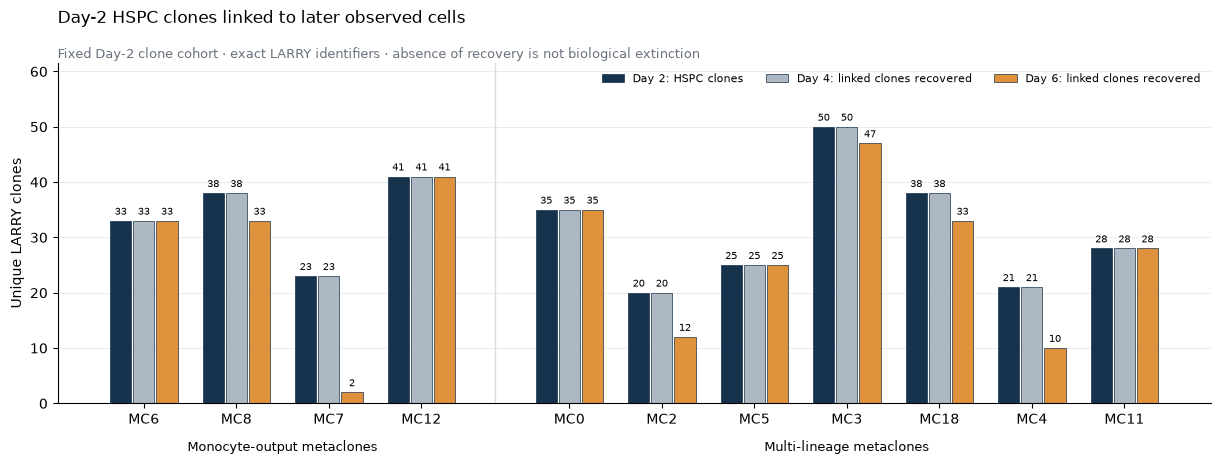

/path/to/ChronoClone/analysis_workspace/analyses/weinreb_metaclone_ancestry_worked_examples_20260910/figures/ancestry_01_day2_clone_linkage.svg


In [8]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
plot_stem = "ancestry_01_day2_clone_linkage"
plot_support = dyn_linkage_support.set_index("metaclone").loc[DYN_DISPLAY_MCS].reset_index()
plot_rows = []
for row in plot_support.itertuples(index=False):
    for day in [2, 4, 6]:
        count = row.n_day2_hspc_clones if day == 2 else getattr(row, f"n_linked_observed_clones_day{day}")
        plot_rows.append({"metaclone": row.metaclone, "lineage_family": row.lineage_family, "day": day,
                          "n_clones": count, "day2_hspc_clone_denominator": row.n_day2_hspc_clones,
                          "n_day2_hspc_cells": row.n_day2_hspc_cells,
                          "n_linked_clones_at_both_day4_and_day6": row.n_linked_clones_at_both_day4_and_day6,
                          "fraction_of_day2_hspc_clones": count / row.n_day2_hspc_clones,
                          "display_order": DYN_DISPLAY_MCS.index(row.metaclone)})
plot_data = pd.DataFrame(plot_rows)
plot_data.to_csv(TABLEDIR / f"{plot_stem}.csv", index=False)
fig, ax = plt.subplots(figsize=(12.6, 5.4))
plot_x = np.arange(len(DYN_DISPLAY_MCS), dtype=float)
plot_x[4:] += 0.6
day_colors = {2: "#17324D", 4: "#AEB8C2", 6: "#E0913C"}
for offset, day in zip([-0.25, 0, 0.25], [2, 4, 6]):
    values = plot_data[plot_data.day.eq(day)].set_index("metaclone").loc[DYN_DISPLAY_MCS, "n_clones"].to_numpy()
    bars = ax.bar(plot_x + offset, values, width=0.23, color=day_colors[day],
                  edgecolor="#17324D", linewidth=0.5,
                  label="Day 2: HSPC clones" if day == 2 else f"Day {day}: linked clones recovered")
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, value + 0.65, str(value), ha="center", va="bottom", fontsize=7.5)
ax.set_xticks(plot_x, [f"MC{mc}" for mc in DYN_DISPLAY_MCS])
ax.set_ylim(0, plot_data.n_clones.max() * 1.23)
ax.set_ylabel("Unique LARRY clones")
ax.set_title("Day-2 HSPC clones linked to later observed cells", loc="left", pad=29)
ax.text(0, 1.015, "Fixed Day-2 clone cohort · exact LARRY identifiers · absence of recovery is not biological extinction",
        transform=ax.transAxes, fontsize=9, color="#68717D")
ax.axvline(3.8, color="#D8DDE3", linewidth=1)
ax.text(np.mean(plot_x[:4]), -0.14, "Monocyte-output metaclones", transform=ax.get_xaxis_transform(), ha="center", fontsize=9)
ax.text(np.mean(plot_x[4:]), -0.14, "Multi-lineage metaclones", transform=ax.get_xaxis_transform(), ha="center", fontsize=9)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#E6E9EC", linewidth=0.6)
ax.set_axisbelow(True)
fig.subplots_adjust(left=0.075, right=0.99, top=0.83, bottom=0.20)
fig.savefig(FIGDIR / f"{plot_stem}.svg", bbox_inches="tight")
fig.savefig(FIGDIR / f"{plot_stem}.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)
print(FIGDIR / f"{plot_stem}.svg")
plot_runtime_audit.append({'notebook_cell_index':15,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


### Audit what “similar monocyte output” means

The existing lineage-family label uses a fixed fine-state-to-output
mapping pooled across sampling days and excludes the mapped `undiff`
compartment from that denominator. It does **not** establish identical Day-6 endpoints.
Below, the original pooled definition is reconstructed alongside full
Day-6 author-state compositions, with progenitors retained, and
complete fine-state compositions. In the primary composition estimate
every observed clone receives equal weight. Pooled-cell fractions are
saved separately for comparison; zero fractions are inserted only for
missing states within an observed clone-day, never for an absent clone.

In [9]:
dyn_output_rows = []
dyn_clone_output_rows = []
for cohort_name, cohort in dyn_cohorts.items():
    for annotation in ["cell_type_weinreb", "cell_type"]:
        states = sorted(dyn_cells[annotation].unique())
        for (mc, clone, day), frame in cohort.groupby(["metaclone", "LARRY_ID", "day"], observed=True):
            counts = frame[annotation].value_counts().reindex(states, fill_value=0)
            for state, count in counts.items():
                dyn_clone_output_rows.append({"cohort": cohort_name, "annotation": annotation,
                    "metaclone": int(mc), "LARRY_ID": str(clone), "day": int(day), "state": state,
                    "n_state_cells": int(count), "n_clone_day_cells": len(frame), "fraction": count / len(frame)})
dyn_clone_output = pd.DataFrame(dyn_clone_output_rows)
dyn_clone_output.to_csv(TABLEDIR / "ancestry_clone_day_full_state_composition.csv.gz", index=False, compression="gzip")
dyn_output_summary = dyn_clone_output.groupby(["cohort", "annotation", "metaclone", "day", "state"], observed=True).agg(
    fraction=("fraction", "mean"), n_clones=("LARRY_ID", "nunique"), n_state_cells=("n_state_cells", "sum"),
    n_total_cells=("n_clone_day_cells", "sum"),
).reset_index()
dyn_output_summary["pooled_cell_fraction"] = dyn_output_summary.n_state_cells / dyn_output_summary.n_total_cells
dyn_output_summary.to_csv(TABLEDIR / "ancestry_full_state_composition_by_cohort_metaclone_day.csv", index=False)
dyn_differentiated_rows = []
for cohort_name, cohort in dyn_cohorts.items():
    for time_scope, days in [("all_sampling_days", [2, 4, 6]), ("later_days_only", [4, 6]), ("day6_only", [6])]:
        for mc, frame in cohort[cohort.day.isin(days)].groupby("metaclone", observed=True):
            mature = frame[frame.differentiated_output_class.ne("undiff")]
            counts = mature.differentiated_output_class.value_counts()
            for state in ["Neu", "Mono", "Ery/Mk", "Baso", "Mast", "Other"]:
                count = int(counts.get(state, 0))
                dyn_differentiated_rows.append({"cohort": cohort_name, "metaclone": int(mc), "time_scope": time_scope,
                    "state": state, "n_state_cells": count, "n_differentiated_cells": len(mature),
                    "n_all_cells": len(frame), "n_observed_clones": frame.LARRY_ID.nunique(),
                    "n_differentiated_informative_clones": mature.LARRY_ID.nunique(),
                    "pooled_differentiated_fraction": count / len(mature) if len(mature) else np.nan,
                    "differentiated_fraction_of_all_cells": len(mature) / len(frame),
                    "denominator": "pooled mapped differentiated cells; fine-state undiff compartment excluded"})
dyn_differentiated_output = pd.DataFrame(dyn_differentiated_rows)
dyn_differentiated_output.to_csv(TABLEDIR / "ancestry_differentiated_output_definition_audit.csv", index=False)
dyn_source_lineage = pd.read_csv(
    "/path/to/ChronoClone/reference_workspace/Figure/fig2/data/fig2h_lineage_bias_map.csv"
)
dyn_legacy_audit = dyn_differentiated_output[
    dyn_differentiated_output.cohort.eq("all_assigned") & dyn_differentiated_output.time_scope.eq("all_sampling_days")
].merge(dyn_source_lineage[["metaclone", "top_output", "top_frac"]], on="metaclone", validate="many_to_one")
dyn_legacy_audit = dyn_legacy_audit[dyn_legacy_audit.state.eq(dyn_legacy_audit.top_output)].copy()
dyn_legacy_audit["matches_original_rounded_fraction"] = (
    dyn_legacy_audit.pooled_differentiated_fraction.round(3) == dyn_legacy_audit.top_frac
)
dyn_legacy_audit.to_csv(TABLEDIR / "ancestry_original_output_fraction_reconstruction.csv", index=False)
dyn_checks["original_pooled_differentiated_fractions_reproduced"] = dyn_legacy_audit.matches_original_rounded_fraction.all()
dyn_output_sums = dyn_output_summary.groupby(["cohort", "annotation", "metaclone", "day"]).fraction.sum()
dyn_checks["full_state_compositions_sum_to_one"] = np.allclose(dyn_output_sums, 1.0)
dyn_checks["clone_full_state_compositions_sum_to_one"] = np.allclose(
    dyn_clone_output.groupby(["cohort", "annotation", "metaclone", "LARRY_ID", "day"]).fraction.sum(), 1.0)
assert all(dyn_checks.values()), dyn_checks
display(dyn_differentiated_output[
    dyn_differentiated_output.cohort.isin(["all_assigned", "day2_hspc_linked"])
    & dyn_differentiated_output.time_scope.eq("all_sampling_days")
    & dyn_differentiated_output.metaclone.isin(DYN_MONO_MCS) & dyn_differentiated_output.state.eq("Mono")
])
display(dyn_output_summary[
    dyn_output_summary.cohort.eq("day2_hspc_linked") & dyn_output_summary.annotation.eq("cell_type_weinreb")
    & dyn_output_summary.day.eq(6) & dyn_output_summary.metaclone.isin(DYN_MONO_MCS)
].pivot(index="metaclone", columns="state", values="fraction").reindex(DYN_MONO_MCS))

,cohort,metaclone,time_scope,state,n_state_cells,n_differentiated_cells,n_all_cells,n_observed_clones,n_differentiated_informative_clones,pooled_differentiated_fraction,differentiated_fraction_of_all_cells,denominator
37,day2_hspc_linked,6,all_sampling_days,Mono,360,383,575,33,33,0.939948,0.666087,pooled mapped differentiated cells; fine-state...
43,day2_hspc_linked,7,all_sampling_days,Mono,81,86,127,23,23,0.941860,0.677165,pooled mapped differentiated cells; fine-state...
49,day2_hspc_linked,8,all_sampling_days,Mono,281,312,533,38,33,0.900641,0.585366,pooled mapped differentiated cells; fine-state...
73,day2_hspc_linked,12,all_sampling_days,Mono,438,467,567,41,41,0.937901,0.823633,pooled mapped differentiated cells; fine-state...
397,all_assigned,6,all_sampling_days,Mono,360,383,575,33,33,0.939948,0.666087,pooled mapped differentiated cells; fine-state...
403,all_assigned,7,all_sampling_days,Mono,81,86,127,23,23,0.941860,0.677165,pooled mapped differentiated cells; fine-state...
409,all_assigned,8,all_sampling_days,Mono,281,312,533,38,33,0.900641,0.585366,pooled mapped differentiated cells; fine-state...
433,all_assigned,12,all_sampling_days,Mono,438,467,567,41,41,0.937901,0.823633,pooled mapped differentiated cells; fine-state...


state,Baso,Ccr7_DC,Eos,Erythroid,Lymphoid,Mast,Meg,Monocyte,Neutrophil,Undifferentiated
metaclone,,,,,,,,,,
6,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.878677,0.010988,0.110336
8,0.0,0.0,0.0,0.0,0.014359,0.0,0.001263,0.803969,0.031902,0.148506
7,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.416667,0.583333,0.000000
12,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.974531,0.015854,0.009615


### Monocyte branch positions in the same ancestry cohort

Each dot below is one clone's median pseudotime among cells passing
the inherited monocyte branch mask at that snapshot. Black horizontal
marks show the median of those clone medians; `n` counts branch-informative
clones. A clone with no cells on this branch contributes to its
occupancy denominator but has no defined branch-position value.
This is a grouped distribution display at three observed snapshots,
not an interpolated time curve or a direct measurement of velocity.
The navy/orange grouping follows the existing MC6/MC8 versus MC7/MC12
comparison; individual metaclones remain separate.

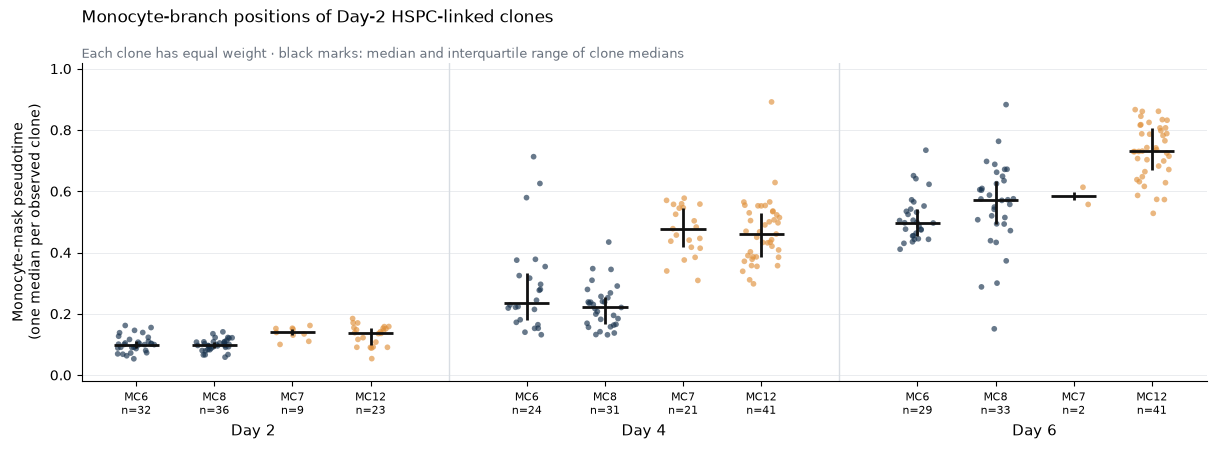

/path/to/ChronoClone/analysis_workspace/analyses/weinreb_metaclone_ancestry_worked_examples_20260910/figures/ancestry_02_monocyte_branch_position.svg


In [10]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
plot_stem = "ancestry_02_monocyte_branch_position"
plot_data = dyn_clone_branch[
    dyn_clone_branch.cohort.eq("day2_hspc_linked") & dyn_clone_branch.metaclone.isin(DYN_MONO_MCS)
    & dyn_clone_branch.branch.eq("Mono")
].copy()
plot_data["display_order"] = plot_data.metaclone.map({mc: i for i, mc in enumerate(DYN_MONO_MCS)})
plot_data["position_defined"] = plot_data.branch_pseudotime_median.notna()
plot_data["x_position"] = plot_data.day.map({2: 0, 4: 5, 6: 10}) + plot_data.display_order
plot_data = plot_data.sort_values(["day", "display_order", "LARRY_ID"])
plot_data.to_csv(TABLEDIR / f"{plot_stem}.csv", index=False)
plot_summary = plot_data.groupby(["metaclone", "day", "x_position"], observed=True).agg(
    n_observed_clones=("LARRY_ID", "size"), n_branch_informative_clones=("branch_pseudotime_median", "count"),
    median_of_clone_medians=("branch_pseudotime_median", "median"),
    lower_quartile=("branch_pseudotime_median", lambda x: x.quantile(0.25)),
    upper_quartile=("branch_pseudotime_median", lambda x: x.quantile(0.75)),
).reset_index().sort_values("x_position")
plot_summary.to_csv(TABLEDIR / f"{plot_stem}_summary.csv", index=False)
fig, ax = plt.subplots(figsize=(12.5, 5.4))
jitter_rng = np.random.default_rng(20260910)
for (mc, day), group in plot_data.groupby(["metaclone", "day"], observed=True):
    finite = group[group.position_defined]
    x = float(group.x_position.iloc[0])
    color = "#17324D" if mc in [6, 8] else "#E0913C"
    jitter = jitter_rng.uniform(-0.24, 0.24, len(finite))
    ax.scatter(x + jitter, finite.branch_pseudotime_median, s=17, color=color,
               alpha=0.65, edgecolors="none", zorder=2)
for row in plot_summary.itertuples(index=False):
    if np.isfinite(row.median_of_clone_medians):
        ax.vlines(row.x_position, row.lower_quartile, row.upper_quartile, color="#111111", linewidth=2.0, zorder=3)
        ax.hlines(row.median_of_clone_medians, row.x_position - 0.29, row.x_position + 0.29,
                  color="#111111", linewidth=2.0, zorder=4)
tick_labels = [f"MC{row.metaclone}\nn={row.n_branch_informative_clones}" for row in plot_summary.itertuples(index=False)]
ax.set_xticks(plot_summary.x_position, tick_labels, fontsize=8)
for xpos, label in [(1.5, "Day 2"), (6.5, "Day 4"), (11.5, "Day 6")]:
    ax.text(xpos, -0.17, label, transform=ax.get_xaxis_transform(), ha="center", fontsize=11)
ax.axvline(4, color="#D8DDE3", linewidth=1)
ax.axvline(9, color="#D8DDE3", linewidth=1)
ax.set_ylim(-0.02, 1.02)
ax.set_xlim(-0.7, 13.7)
ax.set_ylabel("Monocyte-mask pseudotime\n(one median per observed clone)")
ax.set_title("Monocyte-branch positions of Day-2 HSPC-linked clones", loc="left", pad=29)
ax.text(0, 1.015, "Each clone has equal weight · black marks: median and interquartile range of clone medians",
        transform=ax.transAxes, color="#68717D", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#E6E9EC", linewidth=0.6)
ax.set_axisbelow(True)
fig.subplots_adjust(left=0.09, right=0.99, top=0.83, bottom=0.24)
fig.savefig(FIGDIR / f"{plot_stem}.svg", bbox_inches="tight")
fig.savefig(FIGDIR / f"{plot_stem}.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)
print(FIGDIR / f"{plot_stem}.svg")
plot_runtime_audit.append({'notebook_cell_index':19,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


### Multilineage branch occupancy changes

The heatmap compares Day 6 with Day 4 for all seven current multilineage
metaclones in the Day-2 HSPC-linked cohort. Each value is a difference
in mean within-clone occupancy, in percentage points. These are
overlapping branch-compatibility masks, so a cell can contribute to
several columns and columns do not sum to one. Differences compare
destructive snapshots. The full-cohort and same-clones-at-both-days
sensitivities and the pre-existing MC5–MC3 / MC3–MC18 distance
comparisons are saved alongside the primary values. This plot uses
the requested positive red / zero white / negative blue palette;
percentage-point units retain the biological denominator.

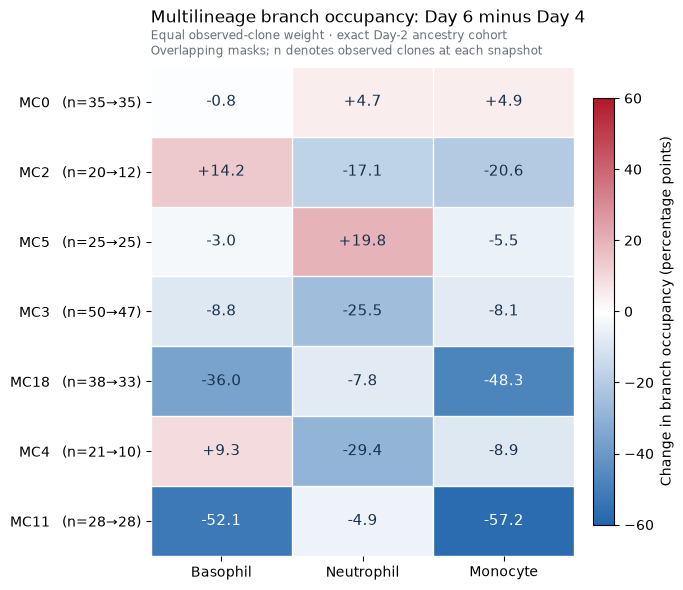

/path/to/ChronoClone/analysis_workspace/analyses/weinreb_metaclone_ancestry_worked_examples_20260910/figures/ancestry_03_multilineage_branch_occupancy_change.svg


In [11]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
plot_stem = "ancestry_03_multilineage_branch_occupancy_change"
plot_long = dyn_branch_summary[
    dyn_branch_summary.metaclone.isin(DYN_MULTI_MCS) & dyn_branch_summary.day.isin([4, 6])
].copy()
plot_wide = plot_long.pivot(index=["cohort", "metaclone", "branch"], columns="day",
                           values=["clone_balanced_occupancy", "n_observed_clones", "n_branch_cells", "n_observed_cells"])
plot_rows = []
for (cohort, mc, branch), row in plot_wide.iterrows():
    plot_rows.append({"cohort": cohort, "metaclone": int(mc), "branch": branch,
        "day4_fraction": row[("clone_balanced_occupancy", 4)], "day6_fraction": row[("clone_balanced_occupancy", 6)],
        "day6_minus_day4_percentage_points": 100 * (row[("clone_balanced_occupancy", 6)] - row[("clone_balanced_occupancy", 4)]),
        "n_day4_observed_clones": int(row[("n_observed_clones", 4)]), "n_day6_observed_clones": int(row[("n_observed_clones", 6)]),
        "n_day4_branch_cells": int(row[("n_branch_cells", 4)]), "n_day6_branch_cells": int(row[("n_branch_cells", 6)]),
        "n_day4_total_cells": int(row[("n_observed_cells", 4)]), "n_day6_total_cells": int(row[("n_observed_cells", 6)]),
        "metaclone_display_order": DYN_MULTI_MCS.index(mc), "branch_display_order": DYN_BRANCHES.index(branch)})
plot_data_all_cohorts = pd.DataFrame(plot_rows)
plot_data_all_cohorts.to_csv(TABLEDIR / f"{plot_stem}_cohort_sensitivities.csv", index=False)
plot_data = plot_data_all_cohorts[plot_data_all_cohorts.cohort.eq("day2_hspc_linked")].copy()
plot_data.to_csv(TABLEDIR / f"{plot_stem}.csv", index=False)
plot_matrix = plot_data.pivot(index="metaclone", columns="branch", values="day6_minus_day4_percentage_points").reindex(index=DYN_MULTI_MCS, columns=DYN_BRANCHES)
plot_limit = max(10.0, float(np.ceil(np.nanmax(np.abs(plot_matrix.to_numpy())) / 10) * 10))
plot_cmap = LinearSegmentedColormap.from_list("ancestry_occupancy_blue_white_red", ["#2166AC", "#FFFFFF", "#B2182B"], N=257)
fig, ax = plt.subplots(figsize=(7.6, 6.7))
im = ax.pcolormesh(np.arange(4) - 0.5, np.arange(len(DYN_MULTI_MCS) + 1) - 0.5,
                   plot_matrix.to_numpy(float), cmap=plot_cmap,
                   norm=TwoSlopeNorm(vmin=-plot_limit, vcenter=0, vmax=plot_limit),
                   shading="flat", rasterized=False)
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(len(DYN_MULTI_MCS) - 0.5, -0.5)
for row_index, mc in enumerate(DYN_MULTI_MCS):
    for col_index, branch in enumerate(DYN_BRANCHES):
        value = float(plot_matrix.loc[mc, branch])
        ax.text(col_index, row_index, f"{value:+.1f}", ha="center", va="center", fontsize=11,
                color="white" if abs(value) > 0.65 * plot_limit else "#17324D")
labels = []
for mc in DYN_MULTI_MCS:
    support = plot_data[plot_data.metaclone.eq(mc)].iloc[0]
    labels.append(f"MC{mc}   (n={int(support.n_day4_observed_clones)}→{int(support.n_day6_observed_clones)})")
ax.set_yticks(range(len(DYN_MULTI_MCS)), labels)
ax.set_xticks(range(3), ["Basophil", "Neutrophil", "Monocyte"])
ax.set_xticks(np.arange(-0.5, 3, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(DYN_MULTI_MCS), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.0)
ax.tick_params(which="minor", bottom=False, left=False)
ax.set_title("Multilineage branch occupancy: Day 6 minus Day 4", loc="left", pad=32, fontsize=12)
ax.text(0, 1.025, "Equal observed-clone weight · exact Day-2 ancestry cohort\nOverlapping masks; n denotes observed clones at each snapshot",
        transform=ax.transAxes, color="#68717D", fontsize=8.5)
colorbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
colorbar.set_label("Change in branch occupancy (percentage points)")
if colorbar.solids is not None:
    colorbar.solids.set_rasterized(False)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.subplots_adjust(left=0.28, right=0.89, top=0.83, bottom=0.10)
fig.savefig(FIGDIR / f"{plot_stem}.svg", bbox_inches="tight")
fig.savefig(FIGDIR / f"{plot_stem}.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)
print(FIGDIR / f"{plot_stem}.svg")
plot_runtime_audit.append({'notebook_cell_index':21,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


In [12]:
# Recompute the two existing temporal examples under every cohort definition.
dyn_distance_rows = []
for cohort in dyn_branch_summary.cohort.unique():
    for mc_a, mc_b, example in [(5, 3, "MC5–MC3 previously described divergence"),
                               (3, 18, "MC3–MC18 previously described convergence")]:
        for estimator in ["clone_balanced_occupancy", "pooled_cell_occupancy"]:
            distances = {}
            for day in [4, 6]:
                frame = dyn_branch_summary[dyn_branch_summary.cohort.eq(cohort) & dyn_branch_summary.day.eq(day)]
                vectors = frame.pivot(index="metaclone", columns="branch", values=estimator).reindex(columns=DYN_BRANCHES)
                distances[day] = float(np.linalg.norm(vectors.loc[mc_a].to_numpy() - vectors.loc[mc_b].to_numpy()))
            dyn_distance_rows.append({"cohort": cohort, "example": example, "metaclone_a": mc_a, "metaclone_b": mc_b,
                "estimator": estimator, "day4_distance": distances[4], "day6_distance": distances[6],
                "distance_change": distances[6] - distances[4],
                "observed_direction": "divergence" if distances[6] > distances[4] else "convergence",
                "coordinate_system": "Euclidean distance in three overlapping Baso/Neu/Mono branch occupancies"})
dyn_pair_distances = pd.DataFrame(dyn_distance_rows)
dyn_pair_distances.to_csv(TABLEDIR / "ancestry_multilineage_branch_pair_distances.csv", index=False)
# Full state-composition distances answer a different question and are retained explicitly.
dyn_state_distance_rows = []
for (cohort, annotation), frame in dyn_output_summary.groupby(["cohort", "annotation"], observed=True):
    for mc_a, mc_b in [(5, 3), (3, 18)]:
        distances = {}
        for day in [4, 6]:
            vectors = frame[frame.day.eq(day)].pivot(index="metaclone", columns="state", values="fraction")
            distances[day] = float(np.linalg.norm(vectors.loc[mc_a].to_numpy() - vectors.loc[mc_b].to_numpy()))
        dyn_state_distance_rows.append({"cohort": cohort, "annotation": annotation, "metaclone_a": mc_a,
            "metaclone_b": mc_b, "day4_distance": distances[4], "day6_distance": distances[6],
            "distance_change": distances[6] - distances[4], "coordinate_system": "Euclidean distance in complete clone-balanced state composition"})
dyn_state_pair_distances = pd.DataFrame(dyn_state_distance_rows)
dyn_state_pair_distances.to_csv(TABLEDIR / "ancestry_multilineage_full_composition_pair_distances.csv", index=False)
dynamics_summary = dyn_branch_summary
linkage_summary = dyn_linkage_support
pair_dynamics_summary = dyn_pair_distances
pd.DataFrame([{"check": key, "passed": bool(value)} for key, value in dyn_checks.items()]).to_csv(
    TABLEDIR / "ancestry_dynamics_validation.csv", index=False)
assert all(dyn_checks.values())
display(dyn_pair_distances[dyn_pair_distances.estimator.eq("clone_balanced_occupancy")])
display(dyn_state_pair_distances[dyn_state_pair_distances.cohort.eq("day2_hspc_linked")])
print("Observed ancestry linkage:", len(dyn_day2_clones), "Day-2 HSPC clones;",
      len(dyn_paired_clones), "also recovered at both later snapshots.")
print("All dynamics above are descriptive associations in an existing temporal partition.",
      "No velocity, survival, prospective fate, or causal effect is estimated.")

,cohort,example,metaclone_a,metaclone_b,estimator,day4_distance,day6_distance,distance_change,observed_direction,coordinate_system
0,all_assigned,MC5–MC3 previously described divergence,5,3,clone_balanced_occupancy,0.367499,0.522587,0.155088,divergence,Euclidean distance in three overlapping Baso/N...
2,all_assigned,MC3–MC18 previously described convergence,3,18,clone_balanced_occupancy,0.441630,0.259673,-0.181958,convergence,Euclidean distance in three overlapping Baso/N...
4,day2_hspc_linked,MC5–MC3 previously described divergence,5,3,clone_balanced_occupancy,0.367499,0.522587,0.155088,divergence,Euclidean distance in three overlapping Baso/N...
6,day2_hspc_linked,MC3–MC18 previously described convergence,3,18,clone_balanced_occupancy,0.441630,0.259673,-0.181958,convergence,Euclidean distance in three overlapping Baso/N...
8,day2_linked_observed_both_later_days,MC5–MC3 previously described divergence,5,3,clone_balanced_occupancy,0.349433,0.522587,0.173154,divergence,Euclidean distance in three overlapping Baso/N...
10,day2_linked_observed_both_later_days,MC3–MC18 previously described convergence,3,18,clone_balanced_occupancy,0.468481,0.259673,-0.208808,convergence,Euclidean distance in three overlapping Baso/N...


,cohort,annotation,metaclone_a,metaclone_b,day4_distance,day6_distance,distance_change,coordinate_system
4,day2_hspc_linked,cell_type,5,3,0.387600,0.442369,0.054769,Euclidean distance in complete clone-balanced ...
5,day2_hspc_linked,cell_type,3,18,0.303364,0.512789,0.209425,Euclidean distance in complete clone-balanced ...
6,day2_hspc_linked,cell_type_weinreb,5,3,0.054853,0.400832,0.345979,Euclidean distance in complete clone-balanced ...
7,day2_hspc_linked,cell_type_weinreb,3,18,0.155776,0.583547,0.427771,Euclidean distance in complete clone-balanced ...


Observed ancestry linkage: 569 Day-2 HSPC clones; 463 also recovered at both later snapshots.
All dynamics above are descriptive associations in an existing temporal partition. No velocity, survival, prospective fate, or causal effect is estimated.


## Molecular worked examples: pooled and metaclone-resolved views

These figures use the fixed program ranking above. A pooled family and its
constituent metaclones show the same clones twice; the two views are not
independent groups and are not compared by a hypothesis test. Distributions
show clone-level scores after subtracting the fitted library contribution,
in the original 569-clone score units. Boxes show the median and interquartile
range, whiskers extend to 1.5 interquartile ranges, and dots retain every clone.

The complete monocyte heatmap uses all fixed Hallmarks and a population
z-score across the four adjusted MC means. Red means a positive row z-score,
white zero, and blue a negative score. Symbols refer to the original
within-family OVR multiple-testing family, not the heatmap colors.

Sensitivity forests compare the same contrast on frozen primary gene/program
scales with pointwise 95% intervals. Unsupported comparisons are labelled NE.
Leading-gene charts algebraically decompose the selected program effect; they
do not introduce gene-level significance tests.

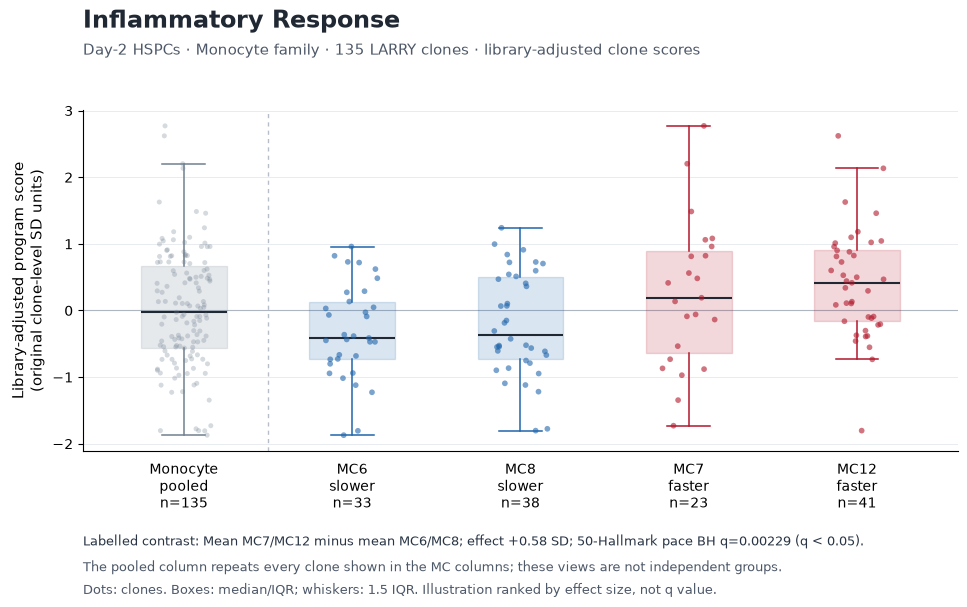

,svg,data,unique_clones,displayed_rows,primary_contrast,primary_qvalue,q_family
0,/path/to/ChronoClone/research...,/path/to/ChronoClone/research...,135,270,Mean MC7/MC12 minus mean MC6/MC8,0.002291,50-Hallmark pace BH


In [13]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: clone-score distributions; pooled and resolved views repeat
# the same cells' clone aggregates. No test compares the repeated x groups.
example_id = 'mono_1'
plot_stem = 'program_01_mono_1_pooled_and_metaclone_distribution'
example = selection.loc[selection.example_id == example_id].iloc[0]
program = str(example.program)
family = str(example.context)
context_flag = 'proliferation-associated curated program' if program.upper().replace('_', ' ').endswith('MYC TARGETS V2') else ''
mc_order = list(MONO_ORDER if family == 'Monocyte' else MULTI_ORDER)
frame = metadata.loc[metadata.metaclone.isin(mc_order)].copy()
frame['library_adjusted_score'] = adjusted_scores.loc[frame.index, program]
frame['clone_id'] = frame.index.astype(str)
frame['program'] = program
frame['example_id'] = example_id
frame['prog2_fraction'] = frame.n_prog_2_cells / frame.n_cells
pooled = frame.assign(display_group=family + ' pooled', display_role='pooled', display_order=0)
resolved = frame.assign(display_group=frame.metaclone.map(lambda x: f'MC{int(x)}'),
                        display_role='metaclone', display_order=frame.metaclone.map({mc: i + 1 for i, mc in enumerate(mc_order)}))
plot_data = pd.concat([pooled, resolved], ignore_index=True)
plot_data['repeated_observation_display'] = True
plot_data['primary_contrast'] = str(example.contrast_label)
plot_data['primary_qvalue'] = float(example.qvalue)
plot_data['primary_q_family'] = '50-Hallmark pace BH' if family == 'Monocyte' else 'original 2,000-test pairwise BH'
plot_data['program_context_flag'] = context_flag
assert plot_data.groupby('clone_id').size().eq(2).all()
assert len(frame) == (135 if family == 'Monocyte' else 217)
groups = [family + ' pooled'] + [f'MC{mc}' for mc in mc_order]
target_mcs = [int(x[2:]) for x in str(example.target_levels).split('|')]
reference_mcs = [int(x[2:]) for x in str(example.reference_levels).split('|')]
colors = ['#708090'] + ['#B2182B' if mc in target_mcs else '#2166AC' if mc in reference_mcs else '#A6ADB7' for mc in mc_order]
labels = [f'{family}\npooled\nn={len(frame)}']
for mc in mc_order:
    role = ('slower' if mc in [6, 8] else 'faster') if family == 'Monocyte' else ('target' if mc in target_mcs else 'reference' if mc in reference_mcs else 'context')
    labels.append(f'MC{mc}\n{role}\nn={int((frame.metaclone == mc).sum())}')
plot_data['group_clone_count'] = plot_data.groupby('display_group').clone_id.transform('nunique')
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)

fig, ax = plt.subplots(figsize=(10.0 if family == 'Monocyte' else 12.0, 6.3))
fig.subplots_adjust(left=0.10, right=0.975, bottom=0.255, top=0.795)
rng = np.random.default_rng(20260910 + 1)
for i, group in enumerate(groups):
    values = plot_data.loc[plot_data.display_group == group, 'library_adjusted_score'].to_numpy(float)
    boxes = ax.boxplot([values], positions=[i], widths=0.51, whis=1.5,
                      showfliers=False, patch_artist=True, manage_ticks=False,
                      medianprops={'color': '#202833', 'linewidth': 1.5},
                      whiskerprops={'color': colors[i], 'linewidth': 1.1},
                      capprops={'color': colors[i], 'linewidth': 1.1},
                      boxprops={'facecolor': colors[i], 'edgecolor': colors[i], 'alpha': 0.17}, zorder=2)
    ax.scatter(i + rng.uniform(-0.16, 0.16, len(values)), values,
               color=colors[i], s=17 if i else 13, alpha=0.60 if i else 0.29,
               edgecolors='none', zorder=3)
ax.axvline(0.5, color='#B7BEC8', linewidth=1.0, linestyle=(0, (3, 3)))
ax.axhline(0, color='#AEB6C2', linewidth=0.8, zorder=1)
ax.set_xticks(np.arange(len(groups)), labels, fontsize=10)
ax.set_xlim(-0.6, len(groups) - 0.4)
ax.set_ylabel('Library-adjusted program score\n(original clone-level SD units)', fontsize=11)
ax.grid(axis='y', color='#E8EBEF', linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis='x', length=0, pad=8)
for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
title = program.replace('HALLMARK_', '').replace('_', ' ')
fig.text(0.10, 0.955, title, ha='left', va='top', fontsize=17, weight='bold', color='#202833')
fig.text(0.10, 0.902, f'Day-2 HSPCs · {family} family · {len(frame)} LARRY clones · library-adjusted clone scores',
         ha='left', va='top', fontsize=11, color='#4D5868')
if context_flag:
    fig.text(0.10, 0.848, 'Context flag: proliferation-associated curated program; no unique metaclone mechanism established.',
             ha='left', va='top', fontsize=10.1, color='#6B4C55')
q = float(example.qvalue)
q_tier = 'q < 0.05' if q < 0.05 else 'exploratory 0.05 ≤ q < 0.10' if q < 0.10 else 'q ≥ 0.10'
q_family = '50-Hallmark pace BH' if family == 'Monocyte' else 'original 2,000-test pairwise BH'
fig.text(0.10, 0.122, f'Labelled contrast: {example.contrast_label}; effect {example.effect_sd:+.2f} SD; {q_family} q={q:.3g} ({q_tier}).',
         ha='left', va='top', fontsize=9.2, color='#283444')
fig.text(0.10, 0.081, 'The pooled column repeats every clone shown in the MC columns; these views are not independent groups.',
         ha='left', va='top', fontsize=9.2, color='#4D5868')
fig.text(0.10, 0.045, 'Dots: clones. Boxes: median/IQR; whiskers: 1.5 IQR. Illustration ranked by effect size, not q value.',
         ha='left', va='top', fontsize=9.2, color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(pd.DataFrame([{'svg': str(FIGDIR / f'{plot_stem}.svg'), 'data': str(TABLEDIR / f'{plot_stem}_plot_data.csv'),
                       'unique_clones': len(frame), 'displayed_rows': len(plot_data), 'primary_contrast': str(example.contrast_label),
                       'primary_qvalue': q, 'q_family': q_family}]))
plot_runtime_audit.append({'notebook_cell_index':24,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


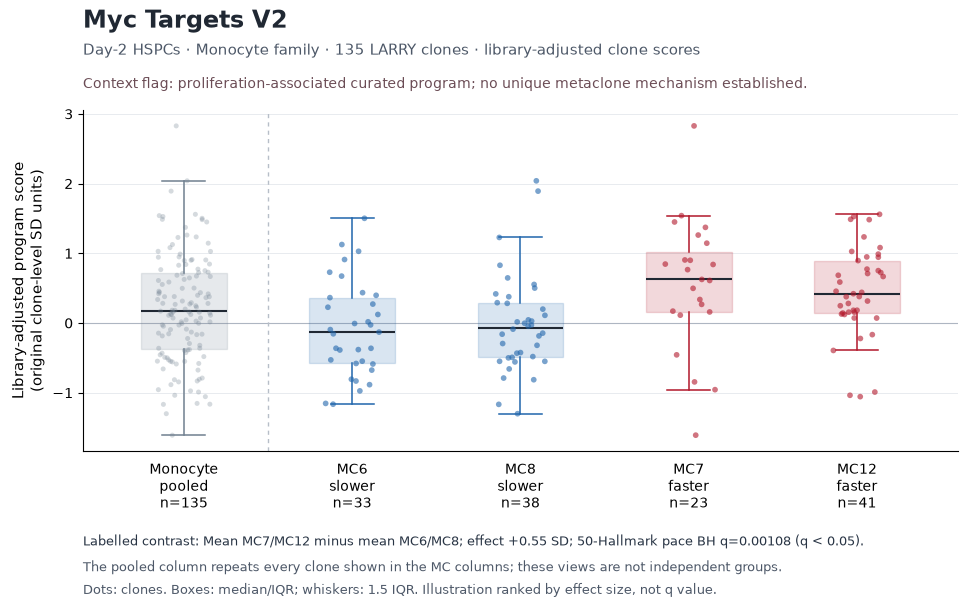

,svg,data,unique_clones,displayed_rows,primary_contrast,primary_qvalue,q_family
0,/path/to/ChronoClone/research...,/path/to/ChronoClone/research...,135,270,Mean MC7/MC12 minus mean MC6/MC8,0.001083,50-Hallmark pace BH


In [14]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: clone-score distributions; pooled and resolved views repeat
# the same cells' clone aggregates. No test compares the repeated x groups.
example_id = 'mono_2'
plot_stem = 'program_02_mono_2_pooled_and_metaclone_distribution'
example = selection.loc[selection.example_id == example_id].iloc[0]
program = str(example.program)
family = str(example.context)
context_flag = 'proliferation-associated curated program' if program.upper().replace('_', ' ').endswith('MYC TARGETS V2') else ''
mc_order = list(MONO_ORDER if family == 'Monocyte' else MULTI_ORDER)
frame = metadata.loc[metadata.metaclone.isin(mc_order)].copy()
frame['library_adjusted_score'] = adjusted_scores.loc[frame.index, program]
frame['clone_id'] = frame.index.astype(str)
frame['program'] = program
frame['example_id'] = example_id
frame['prog2_fraction'] = frame.n_prog_2_cells / frame.n_cells
pooled = frame.assign(display_group=family + ' pooled', display_role='pooled', display_order=0)
resolved = frame.assign(display_group=frame.metaclone.map(lambda x: f'MC{int(x)}'),
                        display_role='metaclone', display_order=frame.metaclone.map({mc: i + 1 for i, mc in enumerate(mc_order)}))
plot_data = pd.concat([pooled, resolved], ignore_index=True)
plot_data['repeated_observation_display'] = True
plot_data['primary_contrast'] = str(example.contrast_label)
plot_data['primary_qvalue'] = float(example.qvalue)
plot_data['primary_q_family'] = '50-Hallmark pace BH' if family == 'Monocyte' else 'original 2,000-test pairwise BH'
plot_data['program_context_flag'] = context_flag
assert plot_data.groupby('clone_id').size().eq(2).all()
assert len(frame) == (135 if family == 'Monocyte' else 217)
groups = [family + ' pooled'] + [f'MC{mc}' for mc in mc_order]
target_mcs = [int(x[2:]) for x in str(example.target_levels).split('|')]
reference_mcs = [int(x[2:]) for x in str(example.reference_levels).split('|')]
colors = ['#708090'] + ['#B2182B' if mc in target_mcs else '#2166AC' if mc in reference_mcs else '#A6ADB7' for mc in mc_order]
labels = [f'{family}\npooled\nn={len(frame)}']
for mc in mc_order:
    role = ('slower' if mc in [6, 8] else 'faster') if family == 'Monocyte' else ('target' if mc in target_mcs else 'reference' if mc in reference_mcs else 'context')
    labels.append(f'MC{mc}\n{role}\nn={int((frame.metaclone == mc).sum())}')
plot_data['group_clone_count'] = plot_data.groupby('display_group').clone_id.transform('nunique')
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)

fig, ax = plt.subplots(figsize=(10.0 if family == 'Monocyte' else 12.0, 6.3))
fig.subplots_adjust(left=0.10, right=0.975, bottom=0.255, top=0.795)
rng = np.random.default_rng(20260910 + 2)
for i, group in enumerate(groups):
    values = plot_data.loc[plot_data.display_group == group, 'library_adjusted_score'].to_numpy(float)
    boxes = ax.boxplot([values], positions=[i], widths=0.51, whis=1.5,
                      showfliers=False, patch_artist=True, manage_ticks=False,
                      medianprops={'color': '#202833', 'linewidth': 1.5},
                      whiskerprops={'color': colors[i], 'linewidth': 1.1},
                      capprops={'color': colors[i], 'linewidth': 1.1},
                      boxprops={'facecolor': colors[i], 'edgecolor': colors[i], 'alpha': 0.17}, zorder=2)
    ax.scatter(i + rng.uniform(-0.16, 0.16, len(values)), values,
               color=colors[i], s=17 if i else 13, alpha=0.60 if i else 0.29,
               edgecolors='none', zorder=3)
ax.axvline(0.5, color='#B7BEC8', linewidth=1.0, linestyle=(0, (3, 3)))
ax.axhline(0, color='#AEB6C2', linewidth=0.8, zorder=1)
ax.set_xticks(np.arange(len(groups)), labels, fontsize=10)
ax.set_xlim(-0.6, len(groups) - 0.4)
ax.set_ylabel('Library-adjusted program score\n(original clone-level SD units)', fontsize=11)
ax.grid(axis='y', color='#E8EBEF', linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis='x', length=0, pad=8)
for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
title = program.replace('HALLMARK_', '').replace('_', ' ')
fig.text(0.10, 0.955, title, ha='left', va='top', fontsize=17, weight='bold', color='#202833')
fig.text(0.10, 0.902, f'Day-2 HSPCs · {family} family · {len(frame)} LARRY clones · library-adjusted clone scores',
         ha='left', va='top', fontsize=11, color='#4D5868')
if context_flag:
    fig.text(0.10, 0.848, 'Context flag: proliferation-associated curated program; no unique metaclone mechanism established.',
             ha='left', va='top', fontsize=10.1, color='#6B4C55')
q = float(example.qvalue)
q_tier = 'q < 0.05' if q < 0.05 else 'exploratory 0.05 ≤ q < 0.10' if q < 0.10 else 'q ≥ 0.10'
q_family = '50-Hallmark pace BH' if family == 'Monocyte' else 'original 2,000-test pairwise BH'
fig.text(0.10, 0.122, f'Labelled contrast: {example.contrast_label}; effect {example.effect_sd:+.2f} SD; {q_family} q={q:.3g} ({q_tier}).',
         ha='left', va='top', fontsize=9.2, color='#283444')
fig.text(0.10, 0.081, 'The pooled column repeats every clone shown in the MC columns; these views are not independent groups.',
         ha='left', va='top', fontsize=9.2, color='#4D5868')
fig.text(0.10, 0.045, 'Dots: clones. Boxes: median/IQR; whiskers: 1.5 IQR. Illustration ranked by effect size, not q value.',
         ha='left', va='top', fontsize=9.2, color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(pd.DataFrame([{'svg': str(FIGDIR / f'{plot_stem}.svg'), 'data': str(TABLEDIR / f'{plot_stem}_plot_data.csv'),
                       'unique_clones': len(frame), 'displayed_rows': len(plot_data), 'primary_contrast': str(example.contrast_label),
                       'primary_qvalue': q, 'q_family': q_family}]))
plot_runtime_audit.append({'notebook_cell_index':25,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


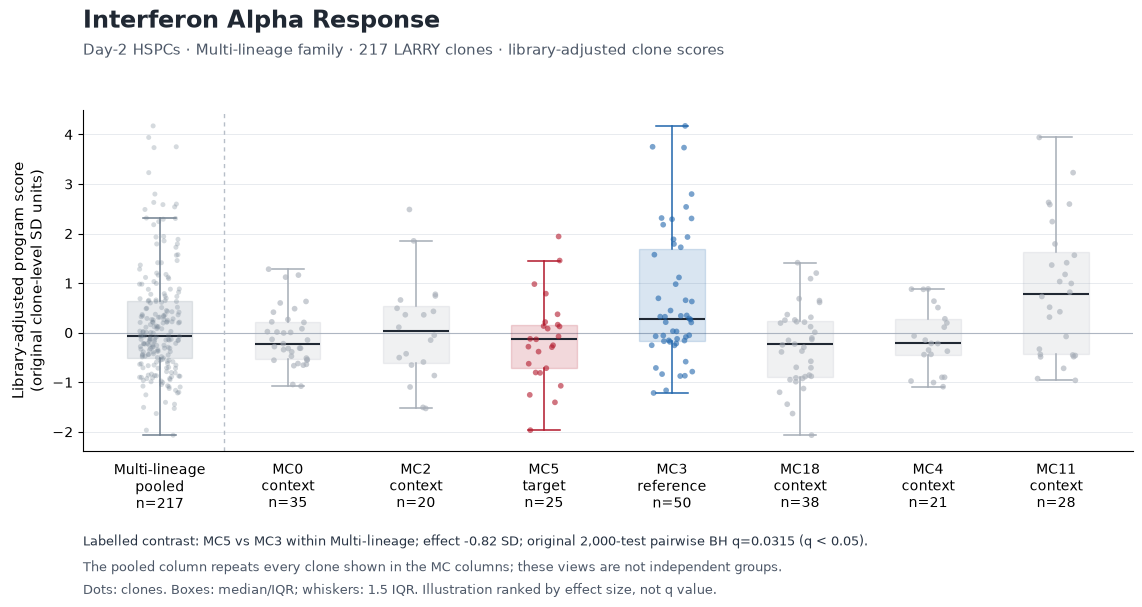

,svg,data,unique_clones,displayed_rows,primary_contrast,primary_qvalue,q_family
0,/path/to/ChronoClone/research...,/path/to/ChronoClone/research...,217,434,MC5 vs MC3 within Multi-lineage,0.031454,"original 2,000-test pairwise BH"


In [15]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: clone-score distributions; pooled and resolved views repeat
# the same cells' clone aggregates. No test compares the repeated x groups.
example_id = 'multi_divergence'
plot_stem = 'program_03_multi_divergence_pooled_and_metaclone_distribution'
example = selection.loc[selection.example_id == example_id].iloc[0]
program = str(example.program)
family = str(example.context)
context_flag = 'proliferation-associated curated program' if program.upper().replace('_', ' ').endswith('MYC TARGETS V2') else ''
mc_order = list(MONO_ORDER if family == 'Monocyte' else MULTI_ORDER)
frame = metadata.loc[metadata.metaclone.isin(mc_order)].copy()
frame['library_adjusted_score'] = adjusted_scores.loc[frame.index, program]
frame['clone_id'] = frame.index.astype(str)
frame['program'] = program
frame['example_id'] = example_id
frame['prog2_fraction'] = frame.n_prog_2_cells / frame.n_cells
pooled = frame.assign(display_group=family + ' pooled', display_role='pooled', display_order=0)
resolved = frame.assign(display_group=frame.metaclone.map(lambda x: f'MC{int(x)}'),
                        display_role='metaclone', display_order=frame.metaclone.map({mc: i + 1 for i, mc in enumerate(mc_order)}))
plot_data = pd.concat([pooled, resolved], ignore_index=True)
plot_data['repeated_observation_display'] = True
plot_data['primary_contrast'] = str(example.contrast_label)
plot_data['primary_qvalue'] = float(example.qvalue)
plot_data['primary_q_family'] = '50-Hallmark pace BH' if family == 'Monocyte' else 'original 2,000-test pairwise BH'
plot_data['program_context_flag'] = context_flag
assert plot_data.groupby('clone_id').size().eq(2).all()
assert len(frame) == (135 if family == 'Monocyte' else 217)
groups = [family + ' pooled'] + [f'MC{mc}' for mc in mc_order]
target_mcs = [int(x[2:]) for x in str(example.target_levels).split('|')]
reference_mcs = [int(x[2:]) for x in str(example.reference_levels).split('|')]
colors = ['#708090'] + ['#B2182B' if mc in target_mcs else '#2166AC' if mc in reference_mcs else '#A6ADB7' for mc in mc_order]
labels = [f'{family}\npooled\nn={len(frame)}']
for mc in mc_order:
    role = ('slower' if mc in [6, 8] else 'faster') if family == 'Monocyte' else ('target' if mc in target_mcs else 'reference' if mc in reference_mcs else 'context')
    labels.append(f'MC{mc}\n{role}\nn={int((frame.metaclone == mc).sum())}')
plot_data['group_clone_count'] = plot_data.groupby('display_group').clone_id.transform('nunique')
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)

fig, ax = plt.subplots(figsize=(10.0 if family == 'Monocyte' else 12.0, 6.3))
fig.subplots_adjust(left=0.10, right=0.975, bottom=0.255, top=0.795)
rng = np.random.default_rng(20260910 + 3)
for i, group in enumerate(groups):
    values = plot_data.loc[plot_data.display_group == group, 'library_adjusted_score'].to_numpy(float)
    boxes = ax.boxplot([values], positions=[i], widths=0.51, whis=1.5,
                      showfliers=False, patch_artist=True, manage_ticks=False,
                      medianprops={'color': '#202833', 'linewidth': 1.5},
                      whiskerprops={'color': colors[i], 'linewidth': 1.1},
                      capprops={'color': colors[i], 'linewidth': 1.1},
                      boxprops={'facecolor': colors[i], 'edgecolor': colors[i], 'alpha': 0.17}, zorder=2)
    ax.scatter(i + rng.uniform(-0.16, 0.16, len(values)), values,
               color=colors[i], s=17 if i else 13, alpha=0.60 if i else 0.29,
               edgecolors='none', zorder=3)
ax.axvline(0.5, color='#B7BEC8', linewidth=1.0, linestyle=(0, (3, 3)))
ax.axhline(0, color='#AEB6C2', linewidth=0.8, zorder=1)
ax.set_xticks(np.arange(len(groups)), labels, fontsize=10)
ax.set_xlim(-0.6, len(groups) - 0.4)
ax.set_ylabel('Library-adjusted program score\n(original clone-level SD units)', fontsize=11)
ax.grid(axis='y', color='#E8EBEF', linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis='x', length=0, pad=8)
for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
title = program.replace('HALLMARK_', '').replace('_', ' ')
fig.text(0.10, 0.955, title, ha='left', va='top', fontsize=17, weight='bold', color='#202833')
fig.text(0.10, 0.902, f'Day-2 HSPCs · {family} family · {len(frame)} LARRY clones · library-adjusted clone scores',
         ha='left', va='top', fontsize=11, color='#4D5868')
if context_flag:
    fig.text(0.10, 0.848, 'Context flag: proliferation-associated curated program; no unique metaclone mechanism established.',
             ha='left', va='top', fontsize=10.1, color='#6B4C55')
q = float(example.qvalue)
q_tier = 'q < 0.05' if q < 0.05 else 'exploratory 0.05 ≤ q < 0.10' if q < 0.10 else 'q ≥ 0.10'
q_family = '50-Hallmark pace BH' if family == 'Monocyte' else 'original 2,000-test pairwise BH'
fig.text(0.10, 0.122, f'Labelled contrast: {example.contrast_label}; effect {example.effect_sd:+.2f} SD; {q_family} q={q:.3g} ({q_tier}).',
         ha='left', va='top', fontsize=9.2, color='#283444')
fig.text(0.10, 0.081, 'The pooled column repeats every clone shown in the MC columns; these views are not independent groups.',
         ha='left', va='top', fontsize=9.2, color='#4D5868')
fig.text(0.10, 0.045, 'Dots: clones. Boxes: median/IQR; whiskers: 1.5 IQR. Illustration ranked by effect size, not q value.',
         ha='left', va='top', fontsize=9.2, color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(pd.DataFrame([{'svg': str(FIGDIR / f'{plot_stem}.svg'), 'data': str(TABLEDIR / f'{plot_stem}_plot_data.csv'),
                       'unique_clones': len(frame), 'displayed_rows': len(plot_data), 'primary_contrast': str(example.contrast_label),
                       'primary_qvalue': q, 'q_family': q_family}]))
plot_runtime_audit.append({'notebook_cell_index':26,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


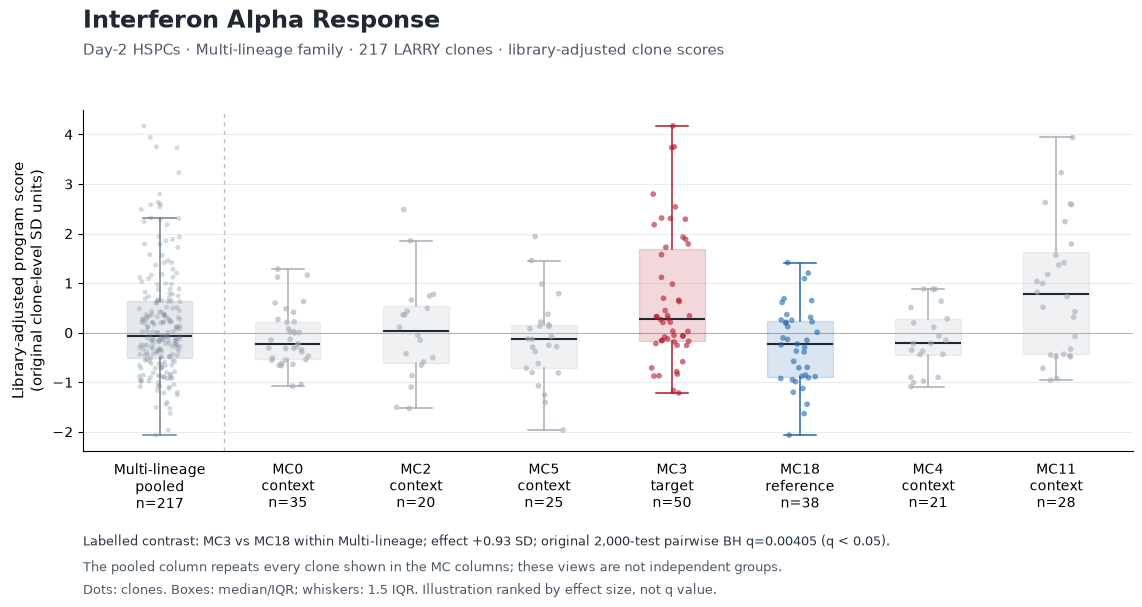

,svg,data,unique_clones,displayed_rows,primary_contrast,primary_qvalue,q_family
0,/path/to/ChronoClone/research...,/path/to/ChronoClone/research...,217,434,MC3 vs MC18 within Multi-lineage,0.004048,"original 2,000-test pairwise BH"


In [16]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: clone-score distributions; pooled and resolved views repeat
# the same cells' clone aggregates. No test compares the repeated x groups.
example_id = 'multi_convergence'
plot_stem = 'program_04_multi_convergence_pooled_and_metaclone_distribution'
example = selection.loc[selection.example_id == example_id].iloc[0]
program = str(example.program)
family = str(example.context)
context_flag = 'proliferation-associated curated program' if program.upper().replace('_', ' ').endswith('MYC TARGETS V2') else ''
mc_order = list(MONO_ORDER if family == 'Monocyte' else MULTI_ORDER)
frame = metadata.loc[metadata.metaclone.isin(mc_order)].copy()
frame['library_adjusted_score'] = adjusted_scores.loc[frame.index, program]
frame['clone_id'] = frame.index.astype(str)
frame['program'] = program
frame['example_id'] = example_id
frame['prog2_fraction'] = frame.n_prog_2_cells / frame.n_cells
pooled = frame.assign(display_group=family + ' pooled', display_role='pooled', display_order=0)
resolved = frame.assign(display_group=frame.metaclone.map(lambda x: f'MC{int(x)}'),
                        display_role='metaclone', display_order=frame.metaclone.map({mc: i + 1 for i, mc in enumerate(mc_order)}))
plot_data = pd.concat([pooled, resolved], ignore_index=True)
plot_data['repeated_observation_display'] = True
plot_data['primary_contrast'] = str(example.contrast_label)
plot_data['primary_qvalue'] = float(example.qvalue)
plot_data['primary_q_family'] = '50-Hallmark pace BH' if family == 'Monocyte' else 'original 2,000-test pairwise BH'
plot_data['program_context_flag'] = context_flag
assert plot_data.groupby('clone_id').size().eq(2).all()
assert len(frame) == (135 if family == 'Monocyte' else 217)
groups = [family + ' pooled'] + [f'MC{mc}' for mc in mc_order]
target_mcs = [int(x[2:]) for x in str(example.target_levels).split('|')]
reference_mcs = [int(x[2:]) for x in str(example.reference_levels).split('|')]
colors = ['#708090'] + ['#B2182B' if mc in target_mcs else '#2166AC' if mc in reference_mcs else '#A6ADB7' for mc in mc_order]
labels = [f'{family}\npooled\nn={len(frame)}']
for mc in mc_order:
    role = ('slower' if mc in [6, 8] else 'faster') if family == 'Monocyte' else ('target' if mc in target_mcs else 'reference' if mc in reference_mcs else 'context')
    labels.append(f'MC{mc}\n{role}\nn={int((frame.metaclone == mc).sum())}')
plot_data['group_clone_count'] = plot_data.groupby('display_group').clone_id.transform('nunique')
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)

fig, ax = plt.subplots(figsize=(10.0 if family == 'Monocyte' else 12.0, 6.3))
fig.subplots_adjust(left=0.10, right=0.975, bottom=0.255, top=0.795)
rng = np.random.default_rng(20260910 + 4)
for i, group in enumerate(groups):
    values = plot_data.loc[plot_data.display_group == group, 'library_adjusted_score'].to_numpy(float)
    boxes = ax.boxplot([values], positions=[i], widths=0.51, whis=1.5,
                      showfliers=False, patch_artist=True, manage_ticks=False,
                      medianprops={'color': '#202833', 'linewidth': 1.5},
                      whiskerprops={'color': colors[i], 'linewidth': 1.1},
                      capprops={'color': colors[i], 'linewidth': 1.1},
                      boxprops={'facecolor': colors[i], 'edgecolor': colors[i], 'alpha': 0.17}, zorder=2)
    ax.scatter(i + rng.uniform(-0.16, 0.16, len(values)), values,
               color=colors[i], s=17 if i else 13, alpha=0.60 if i else 0.29,
               edgecolors='none', zorder=3)
ax.axvline(0.5, color='#B7BEC8', linewidth=1.0, linestyle=(0, (3, 3)))
ax.axhline(0, color='#AEB6C2', linewidth=0.8, zorder=1)
ax.set_xticks(np.arange(len(groups)), labels, fontsize=10)
ax.set_xlim(-0.6, len(groups) - 0.4)
ax.set_ylabel('Library-adjusted program score\n(original clone-level SD units)', fontsize=11)
ax.grid(axis='y', color='#E8EBEF', linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis='x', length=0, pad=8)
for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
title = program.replace('HALLMARK_', '').replace('_', ' ')
fig.text(0.10, 0.955, title, ha='left', va='top', fontsize=17, weight='bold', color='#202833')
fig.text(0.10, 0.902, f'Day-2 HSPCs · {family} family · {len(frame)} LARRY clones · library-adjusted clone scores',
         ha='left', va='top', fontsize=11, color='#4D5868')
if context_flag:
    fig.text(0.10, 0.848, 'Context flag: proliferation-associated curated program; no unique metaclone mechanism established.',
             ha='left', va='top', fontsize=10.1, color='#6B4C55')
q = float(example.qvalue)
q_tier = 'q < 0.05' if q < 0.05 else 'exploratory 0.05 ≤ q < 0.10' if q < 0.10 else 'q ≥ 0.10'
q_family = '50-Hallmark pace BH' if family == 'Monocyte' else 'original 2,000-test pairwise BH'
fig.text(0.10, 0.122, f'Labelled contrast: {example.contrast_label}; effect {example.effect_sd:+.2f} SD; {q_family} q={q:.3g} ({q_tier}).',
         ha='left', va='top', fontsize=9.2, color='#283444')
fig.text(0.10, 0.081, 'The pooled column repeats every clone shown in the MC columns; these views are not independent groups.',
         ha='left', va='top', fontsize=9.2, color='#4D5868')
fig.text(0.10, 0.045, 'Dots: clones. Boxes: median/IQR; whiskers: 1.5 IQR. Illustration ranked by effect size, not q value.',
         ha='left', va='top', fontsize=9.2, color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(pd.DataFrame([{'svg': str(FIGDIR / f'{plot_stem}.svg'), 'data': str(TABLEDIR / f'{plot_stem}_plot_data.csv'),
                       'unique_clones': len(frame), 'displayed_rows': len(plot_data), 'primary_contrast': str(example.contrast_label),
                       'primary_qvalue': q, 'q_family': q_family}]))
plot_runtime_audit.append({'notebook_cell_index':27,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


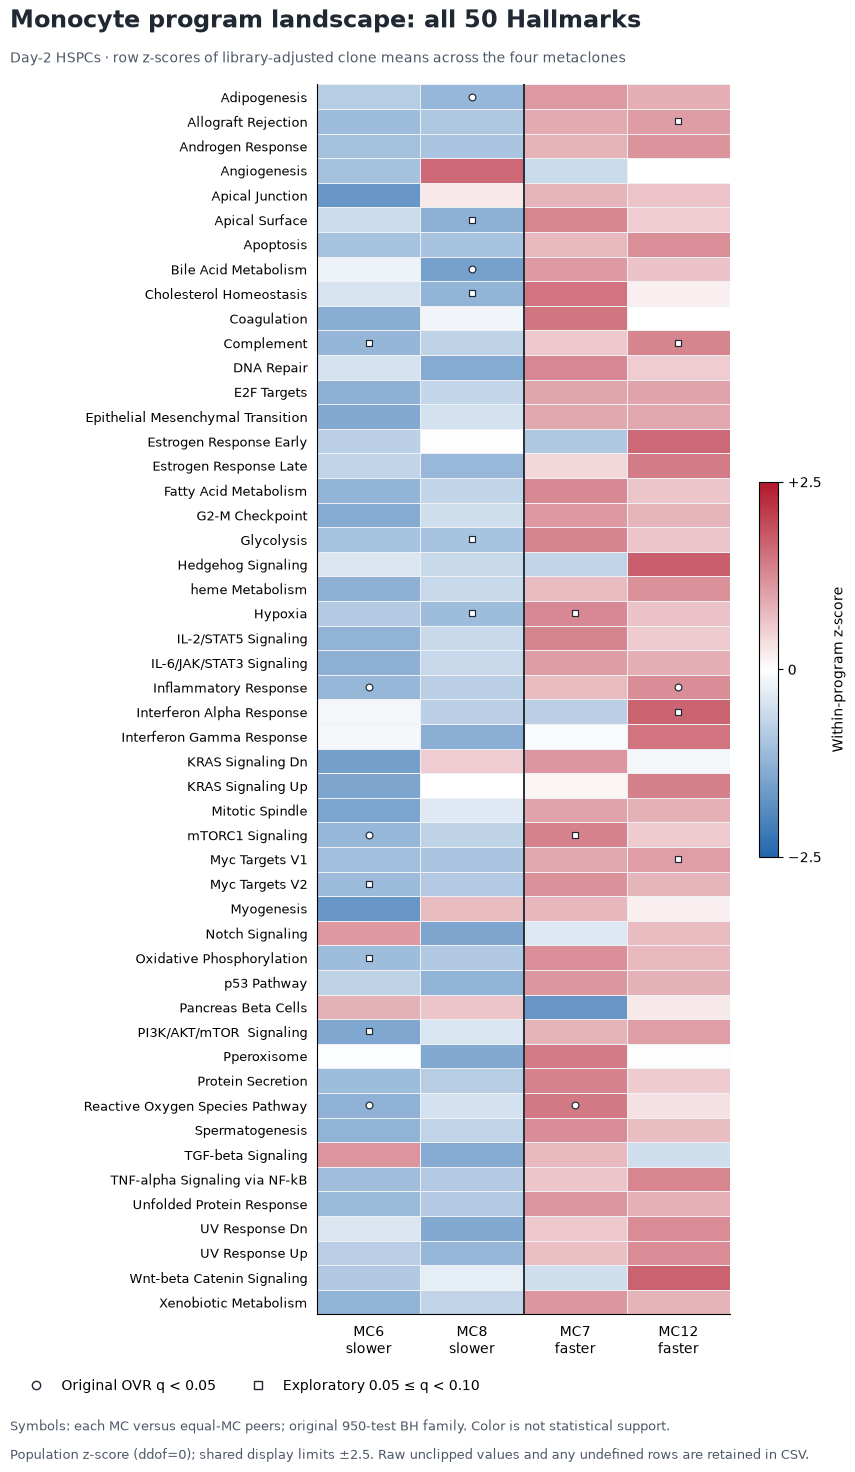

,svg,data,programs,tiles,clipped_tiles,undefined_tiles
0,/path/to/ChronoClone/research...,/path/to/ChronoClone/research...,50,200,0,0


In [17]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: all fixed programs, population z-score of four fitted means.
# An FDR symbol applies to a separately fitted MC-versus-peer contrast.
plot_stem = 'program_05_monocyte_all50_row_zscore_heatmap'
ordered_programs = sorted(PROGRAMS, key=lambda p: str(p).casefold())
means = adjusted_means.loc[MONO_ORDER, ordered_programs].T.copy()
center = means.mean(axis=1)
scale = means.std(axis=1, ddof=0)
z = means.sub(center, axis=0).div(scale.where(scale > 1e-12), axis=0)
ovrs = primary[(primary.tier == 'within_lineage_ovr') & (primary.lineage_bias == 'Monocyte')].copy()
ovrs['metaclone'] = ovrs.target_levels.str.replace('MC', '', regex=False).astype(int)
ovrs = ovrs.set_index(['program', 'metaclone'])
records = []
for row_i, program in enumerate(ordered_programs):
    for column_i, mc in enumerate(MONO_ORDER):
        test = ovrs.loc[(program, mc)]
        value = float(z.loc[program, mc])
        records.append({'program': program, 'metaclone': mc, 'row_order': row_i, 'column_order': column_i,
                        'adjusted_program_mean_sd': float(means.loc[program, mc]), 'row_center': float(center.loc[program]),
                        'row_scale': float(scale.loc[program]), 'zscore_ddof': 0, 'raw_zscore': value,
                        'display_zscore': np.clip(value, -2.5, 2.5), 'was_clipped': bool(abs(value) > 2.5),
                        'zscore_estimable': bool(scale.loc[program] > 1e-12),
                        'undefined_reason': '' if scale.loc[program] > 1e-12 else 'constant adjusted means across four MCs',
                        'contrast_id': test.contrast_id, 'original_950_test_OVR_qvalue': float(test.qvalue),
                        'contrast_support_gate': bool(test.support_gate), 'effect_sd': float(test.effect_sd),
                        'symbol': 'circle' if test.support_gate and test.qvalue < 0.05 else 'square' if test.support_gate and test.qvalue < 0.10 else ''})
plot_data = pd.DataFrame(records)
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)
cmap = mpl.colors.LinearSegmentedColormap.from_list('program_all50_blue_white_red', ['#2166AC', '#FFFFFF', '#B2182B'], N=257)
cmap.set_bad('#D9DEE5')
norm = mpl.colors.TwoSlopeNorm(vmin=-2.5, vcenter=0, vmax=2.5)
assert mpl.colors.to_hex(cmap(norm(0))) == '#ffffff'
fig, ax = plt.subplots(figsize=(9.6, 15.0))
fig.subplots_adjust(left=0.40, right=0.83, bottom=0.105, top=0.925)
mesh = ax.pcolormesh(np.arange(5), np.arange(len(ordered_programs) + 1),
                     z.to_numpy(), cmap=cmap, norm=norm, shading='flat',
                     edgecolors='#EEF0F3', linewidth=0.40, rasterized=False)
ax.set_ylim(len(ordered_programs), 0)
ax.set_xticks(np.arange(4) + 0.5, [f'MC{mc}\n' + ('slower' if mc in [6, 8] else 'faster') for mc in MONO_ORDER], fontsize=10)
ax.set_yticks(np.arange(len(ordered_programs)) + 0.5,
              [str(p).replace('HALLMARK_', '').replace('_', ' ') for p in ordered_programs], fontsize=9.4)
ax.tick_params(axis='both', length=0, pad=7)
ax.axvline(2, color='#202833', linewidth=1.35)
for symbol, marker in [('circle', 'o'), ('square', 's')]:
    chosen = plot_data[plot_data.symbol == symbol]
    ax.scatter(chosen.column_order + 0.5, chosen.row_order + 0.5,
               marker=marker, s=24 if marker == 'o' else 22, facecolors='white',
               edgecolors='#202833', linewidths=0.85, zorder=4)
cax = fig.add_axes([0.86, 0.41, 0.020, 0.25])
colorbar = fig.colorbar(mesh, cax=cax, ticks=[-2.5, 0, 2.5])
if colorbar.solids is not None:
    colorbar.solids.set_rasterized(False)
colorbar.set_label('Within-program z-score', fontsize=10, labelpad=7)
colorbar.ax.set_yticklabels(['−2.5', '0', '+2.5'])
fig.text(0.08, 0.975, 'Monocyte program landscape: all 50 Hallmarks', ha='left', va='top',
         fontsize=17, weight='bold', color='#202833')
fig.text(0.08, 0.947, 'Day-2 HSPCs · row z-scores of library-adjusted clone means across the four metaclones',
         ha='left', va='top', fontsize=10.4, color='#4D5868')
legend_handles = [mpl.lines.Line2D([], [], marker='o', linestyle='none', markerfacecolor='white', markeredgecolor='#202833', label='Original OVR q < 0.05'),
                  mpl.lines.Line2D([], [], marker='s', linestyle='none', markerfacecolor='white', markeredgecolor='#202833', label='Exploratory 0.05 ≤ q < 0.10')]
fig.legend(handles=legend_handles, loc='lower left', bbox_to_anchor=(0.08, 0.044), ncol=2, frameon=False, fontsize=10)
fig.text(0.08, 0.035, 'Symbols: each MC versus equal-MC peers; original 950-test BH family. Color is not statistical support.',
         fontsize=9.3, ha='left', va='top', color='#4D5868')
fig.text(0.08, 0.016, 'Population z-score (ddof=0); shared display limits ±2.5. Raw unclipped values and any undefined rows are retained in CSV.',
         fontsize=9.3, ha='left', va='top', color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(pd.DataFrame([{'svg': str(FIGDIR / f'{plot_stem}.svg'), 'data': str(TABLEDIR / f'{plot_stem}_plot_data.csv'),
                       'programs': len(ordered_programs), 'tiles': len(plot_data), 'clipped_tiles': int(plot_data.was_clipped.sum()),
                       'undefined_tiles': int((~plot_data.zscore_estimable).sum())}]))
plot_runtime_audit.append({'notebook_cell_index':28,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


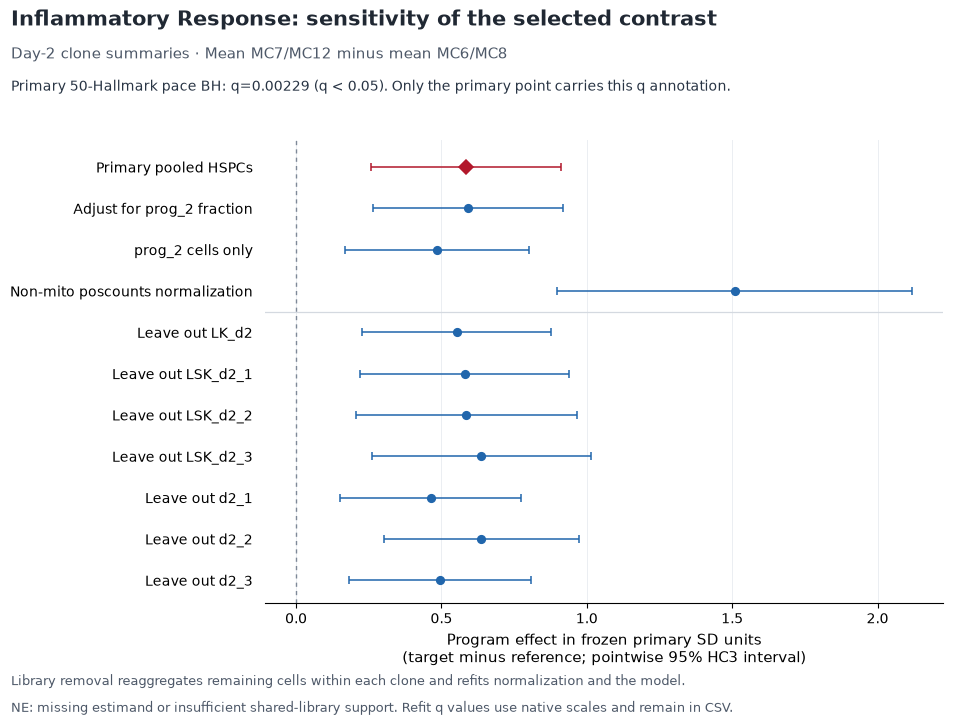

,variant_label,effect_primary_scale,ci_low_primary_scale,ci_high_primary_scale,display_supported
0,Primary pooled HSPCs,0.584366,0.258275,0.910457,True
1,Adjust for prog_2 fraction,0.591816,0.264013,0.919619,True
2,prog_2 cells only,0.483511,0.167554,0.799468,True
3,Non-mito poscounts normalization,1.509380,0.898797,2.119964,True
4,Leave out LK_d2,0.552029,0.228231,0.875828,True
5,Leave out LSK_d2_1,0.579532,0.219063,0.940001,True
6,Leave out LSK_d2_2,0.585541,0.205352,0.965729,True
7,Leave out LSK_d2_3,0.637144,0.260394,1.013895,True
8,Leave out d2_1,0.463644,0.152772,0.774516,True
9,Leave out d2_2,0.637745,0.302885,0.972606,True


/path/to/ChronoClone/analysis_workspace/analyses/weinreb_metaclone_ancestry_worked_examples_20260910/figures/program_06_mono_1_sensitivity_forest.svg


In [18]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: one contrast across primary, source, and true cell-removal
# refits; effects and pointwise intervals use frozen primary gene/program SDs.
example_id = 'mono_1'
plot_stem = 'program_06_mono_1_sensitivity_forest'
example = selection.loc[selection.example_id == example_id].iloc[0]
program, contrast_id = str(example.program), str(example.contrast_id)
primary_row = primary[(primary.program == program) & (primary.contrast_id == contrast_id)].iloc[0]
rows = [{'variant': 'primary', 'variant_label': 'Primary pooled HSPCs', 'display_order': 0,
         'effect_primary_scale': float(primary_row.effect_sd), 'primary_scale_se': float(primary_row.standard_error),
         'support_gate': bool(primary_row.support_gate), 'estimable': bool(primary_row.estimable),
         'native_score_qvalue': float(primary_row.qvalue), 'q_scale': 'primary score scale',
         'shared_libraries': str(primary_row.shared_libraries)}]
candidates = sensitivity[(sensitivity.program == program) & (sensitivity.contrast_id == contrast_id)].copy()
normalization_variants = ['nonmito_poscounts'] if 'nonmito_poscounts' in set(candidates.variant) else []
variants = ['source_fraction_adjusted', 'prog2_only'] + normalization_variants + sorted(candidates.loc[candidates.variant.str.startswith('without_library__'), 'variant'].unique())
for position, variant in enumerate(variants, 1):
    r = candidates.loc[candidates.variant == variant].iloc[0]
    label = 'Adjust for prog_2 fraction' if variant == 'source_fraction_adjusted' else 'prog_2 cells only' if variant == 'prog2_only' else 'Non-mito poscounts normalization' if variant == 'nonmito_poscounts' else 'Leave out ' + (str(r.removed_library) if 'removed_library' in r and pd.notna(r.removed_library) and str(r.removed_library) else variant.replace('without_library__', ''))
    rows.append({'variant': variant, 'variant_label': label, 'display_order': position,
                 'effect_primary_scale': float(r.effect_primary_scale), 'primary_scale_se': float(r.primary_scale_se),
                 'support_gate': bool(r.support_gate), 'estimable': bool(r.estimable),
                 'native_score_qvalue': float(r.fit_tier_fdr), 'q_scale': 'native refit scale; not the plotted frozen-scale CI',
                 'shared_libraries': str(r.shared_libraries)})
plot_data = pd.DataFrame(rows)
plot_data['program'] = program
plot_data['contrast_id'] = contrast_id
plot_data['example_id'] = example_id
plot_data['ci_low_primary_scale'] = plot_data.effect_primary_scale - 1.959963984540054 * plot_data.primary_scale_se
plot_data['ci_high_primary_scale'] = plot_data.effect_primary_scale + 1.959963984540054 * plot_data.primary_scale_se
plot_data['interval_type'] = 'pointwise 95% HC3 normal interval; frozen primary gene/program scale'
plot_data['display_supported'] = plot_data.support_gate & plot_data.estimable & np.isfinite(plot_data.effect_primary_scale) & np.isfinite(plot_data.primary_scale_se)
plot_data['undefined_reason'] = np.where(plot_data.display_supported, '', 'not estimable or insufficient shared-library support')
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)

fig, ax = plt.subplots(figsize=(11.3, 7.65 if normalization_variants else 7.2))
fig.subplots_adjust(left=0.30, right=0.90, bottom=0.18, top=0.785)
ax.axvline(0, color='#7E8998', linewidth=1.0, linestyle=(0, (3, 3)), zorder=1)
ax.axhline(2.5 + len(normalization_variants), color='#D4D9E0', linewidth=0.9, zorder=1)
for r in plot_data.itertuples(index=False):
    if r.display_supported:
        is_primary = r.variant == 'primary'
        color = '#B2182B' if is_primary else '#2166AC'
        ax.errorbar(r.effect_primary_scale, r.display_order,
                    xerr=1.959963984540054 * r.primary_scale_se, fmt='D' if is_primary else 'o',
                    color=color, markerfacecolor=color if not is_primary or primary_row.qvalue < .05 else 'white',
                    markersize=7 if is_primary else 5.5, capsize=3, elinewidth=1.1, markeredgewidth=1.1, zorder=3)
    else:
        ax.text(0.025, r.display_order, 'NE', transform=ax.get_yaxis_transform(),
                ha='left', va='center', fontsize=10, color='#677384', weight='bold')
ax.set_yticks(plot_data.display_order, plot_data.variant_label, fontsize=10.3)
ax.set_ylim(len(plot_data) - 0.45, -0.65)
ax.set_xlabel('Program effect in frozen primary SD units\n(target minus reference; pointwise 95% HC3 interval)', fontsize=10.5)
ax.grid(axis='x', color='#EBEEF2', linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0, pad=9)
title = program.replace('HALLMARK_', '').replace('_', ' ')
fig.text(0.075, 0.956, title + ': sensitivity of the selected contrast', ha='left', va='top',
         fontsize=15.3, weight='bold', color='#202833')
fig.text(0.075, 0.907, f'Day-2 clone summaries · {example.contrast_label}', ha='left', va='top', fontsize=11, color='#4D5868')
q_family = '50-Hallmark pace BH' if example.context == 'Monocyte' else 'original 2,000-test pairwise BH'
q = float(primary_row.qvalue)
q_tier = 'q < 0.05' if q < .05 else 'exploratory 0.05 ≤ q < 0.10' if q < .10 else 'q ≥ 0.10'
fig.text(0.075, 0.864, f'Primary {q_family}: q={q:.3g} ({q_tier}). Only the primary point carries this q annotation.',
         ha='left', va='top', fontsize=10.1, color='#283444')
fig.text(0.075, 0.087, 'Library removal reaggregates remaining cells within each clone and refits normalization and the model.',
         ha='left', va='top', fontsize=9.4, color='#4D5868')
fig.text(0.075, 0.052, 'NE: missing estimand or insufficient shared-library support. Refit q values use native scales and remain in CSV.',
         ha='left', va='top', fontsize=9.4, color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(plot_data[['variant_label', 'effect_primary_scale', 'ci_low_primary_scale', 'ci_high_primary_scale', 'display_supported']])
print(FIGDIR / f'{plot_stem}.svg')
plot_runtime_audit.append({'notebook_cell_index':29,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


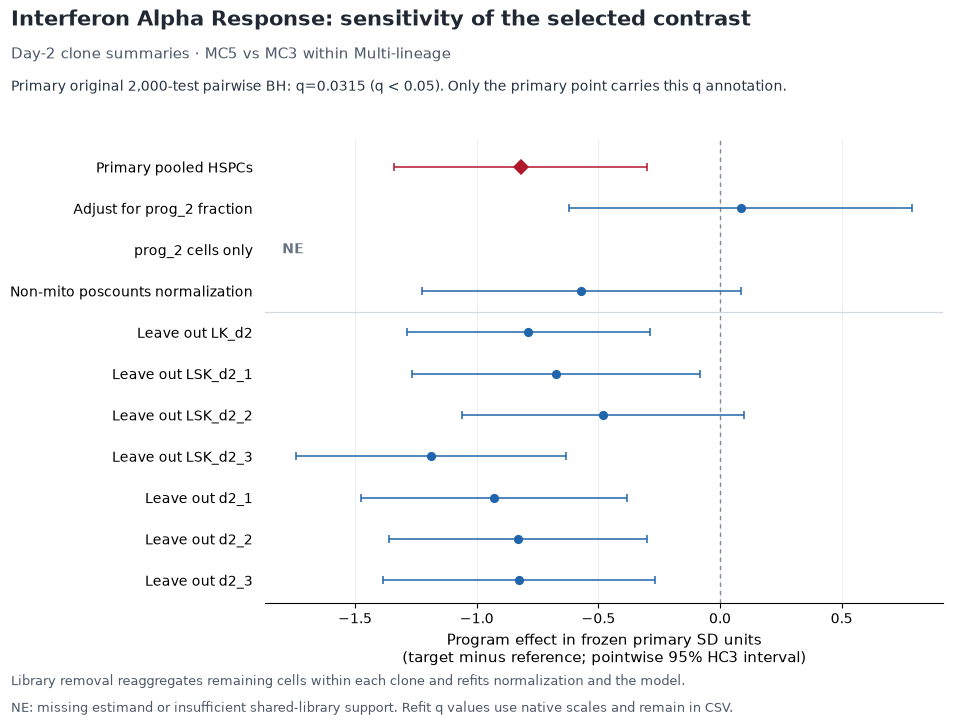

,variant_label,effect_primary_scale,ci_low_primary_scale,ci_high_primary_scale,display_supported
0,Primary pooled HSPCs,-0.818470,-1.338296,-0.298645,True
1,Adjust for prog_2 fraction,0.084868,-0.621197,0.790933,True
2,prog_2 cells only,0.326580,-0.674792,1.327951,False
3,Non-mito poscounts normalization,-0.569284,-1.224349,0.085781,True
4,Leave out LK_d2,-0.787122,-1.286930,-0.287314,True
5,Leave out LSK_d2_1,-0.675093,-1.266057,-0.084129,True
6,Leave out LSK_d2_2,-0.481760,-1.060713,0.097193,True
7,Leave out LSK_d2_3,-1.187400,-1.742230,-0.632570,True
8,Leave out d2_1,-0.929402,-1.477036,-0.381767,True
9,Leave out d2_2,-0.831630,-1.361307,-0.301954,True


/path/to/ChronoClone/analysis_workspace/analyses/weinreb_metaclone_ancestry_worked_examples_20260910/figures/program_07_multi_divergence_sensitivity_forest.svg


In [19]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: one contrast across primary, source, and true cell-removal
# refits; effects and pointwise intervals use frozen primary gene/program SDs.
example_id = 'multi_divergence'
plot_stem = 'program_07_multi_divergence_sensitivity_forest'
example = selection.loc[selection.example_id == example_id].iloc[0]
program, contrast_id = str(example.program), str(example.contrast_id)
primary_row = primary[(primary.program == program) & (primary.contrast_id == contrast_id)].iloc[0]
rows = [{'variant': 'primary', 'variant_label': 'Primary pooled HSPCs', 'display_order': 0,
         'effect_primary_scale': float(primary_row.effect_sd), 'primary_scale_se': float(primary_row.standard_error),
         'support_gate': bool(primary_row.support_gate), 'estimable': bool(primary_row.estimable),
         'native_score_qvalue': float(primary_row.qvalue), 'q_scale': 'primary score scale',
         'shared_libraries': str(primary_row.shared_libraries)}]
candidates = sensitivity[(sensitivity.program == program) & (sensitivity.contrast_id == contrast_id)].copy()
normalization_variants = ['nonmito_poscounts'] if 'nonmito_poscounts' in set(candidates.variant) else []
variants = ['source_fraction_adjusted', 'prog2_only'] + normalization_variants + sorted(candidates.loc[candidates.variant.str.startswith('without_library__'), 'variant'].unique())
for position, variant in enumerate(variants, 1):
    r = candidates.loc[candidates.variant == variant].iloc[0]
    label = 'Adjust for prog_2 fraction' if variant == 'source_fraction_adjusted' else 'prog_2 cells only' if variant == 'prog2_only' else 'Non-mito poscounts normalization' if variant == 'nonmito_poscounts' else 'Leave out ' + (str(r.removed_library) if 'removed_library' in r and pd.notna(r.removed_library) and str(r.removed_library) else variant.replace('without_library__', ''))
    rows.append({'variant': variant, 'variant_label': label, 'display_order': position,
                 'effect_primary_scale': float(r.effect_primary_scale), 'primary_scale_se': float(r.primary_scale_se),
                 'support_gate': bool(r.support_gate), 'estimable': bool(r.estimable),
                 'native_score_qvalue': float(r.fit_tier_fdr), 'q_scale': 'native refit scale; not the plotted frozen-scale CI',
                 'shared_libraries': str(r.shared_libraries)})
plot_data = pd.DataFrame(rows)
plot_data['program'] = program
plot_data['contrast_id'] = contrast_id
plot_data['example_id'] = example_id
plot_data['ci_low_primary_scale'] = plot_data.effect_primary_scale - 1.959963984540054 * plot_data.primary_scale_se
plot_data['ci_high_primary_scale'] = plot_data.effect_primary_scale + 1.959963984540054 * plot_data.primary_scale_se
plot_data['interval_type'] = 'pointwise 95% HC3 normal interval; frozen primary gene/program scale'
plot_data['display_supported'] = plot_data.support_gate & plot_data.estimable & np.isfinite(plot_data.effect_primary_scale) & np.isfinite(plot_data.primary_scale_se)
plot_data['undefined_reason'] = np.where(plot_data.display_supported, '', 'not estimable or insufficient shared-library support')
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)

fig, ax = plt.subplots(figsize=(11.3, 7.65 if normalization_variants else 7.2))
fig.subplots_adjust(left=0.30, right=0.90, bottom=0.18, top=0.785)
ax.axvline(0, color='#7E8998', linewidth=1.0, linestyle=(0, (3, 3)), zorder=1)
ax.axhline(2.5 + len(normalization_variants), color='#D4D9E0', linewidth=0.9, zorder=1)
for r in plot_data.itertuples(index=False):
    if r.display_supported:
        is_primary = r.variant == 'primary'
        color = '#B2182B' if is_primary else '#2166AC'
        ax.errorbar(r.effect_primary_scale, r.display_order,
                    xerr=1.959963984540054 * r.primary_scale_se, fmt='D' if is_primary else 'o',
                    color=color, markerfacecolor=color if not is_primary or primary_row.qvalue < .05 else 'white',
                    markersize=7 if is_primary else 5.5, capsize=3, elinewidth=1.1, markeredgewidth=1.1, zorder=3)
    else:
        ax.text(0.025, r.display_order, 'NE', transform=ax.get_yaxis_transform(),
                ha='left', va='center', fontsize=10, color='#677384', weight='bold')
ax.set_yticks(plot_data.display_order, plot_data.variant_label, fontsize=10.3)
ax.set_ylim(len(plot_data) - 0.45, -0.65)
ax.set_xlabel('Program effect in frozen primary SD units\n(target minus reference; pointwise 95% HC3 interval)', fontsize=10.5)
ax.grid(axis='x', color='#EBEEF2', linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0, pad=9)
title = program.replace('HALLMARK_', '').replace('_', ' ')
fig.text(0.075, 0.956, title + ': sensitivity of the selected contrast', ha='left', va='top',
         fontsize=15.3, weight='bold', color='#202833')
fig.text(0.075, 0.907, f'Day-2 clone summaries · {example.contrast_label}', ha='left', va='top', fontsize=11, color='#4D5868')
q_family = '50-Hallmark pace BH' if example.context == 'Monocyte' else 'original 2,000-test pairwise BH'
q = float(primary_row.qvalue)
q_tier = 'q < 0.05' if q < .05 else 'exploratory 0.05 ≤ q < 0.10' if q < .10 else 'q ≥ 0.10'
fig.text(0.075, 0.864, f'Primary {q_family}: q={q:.3g} ({q_tier}). Only the primary point carries this q annotation.',
         ha='left', va='top', fontsize=10.1, color='#283444')
fig.text(0.075, 0.087, 'Library removal reaggregates remaining cells within each clone and refits normalization and the model.',
         ha='left', va='top', fontsize=9.4, color='#4D5868')
fig.text(0.075, 0.052, 'NE: missing estimand or insufficient shared-library support. Refit q values use native scales and remain in CSV.',
         ha='left', va='top', fontsize=9.4, color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(plot_data[['variant_label', 'effect_primary_scale', 'ci_low_primary_scale', 'ci_high_primary_scale', 'display_supported']])
print(FIGDIR / f'{plot_stem}.svg')
plot_runtime_audit.append({'notebook_cell_index':30,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


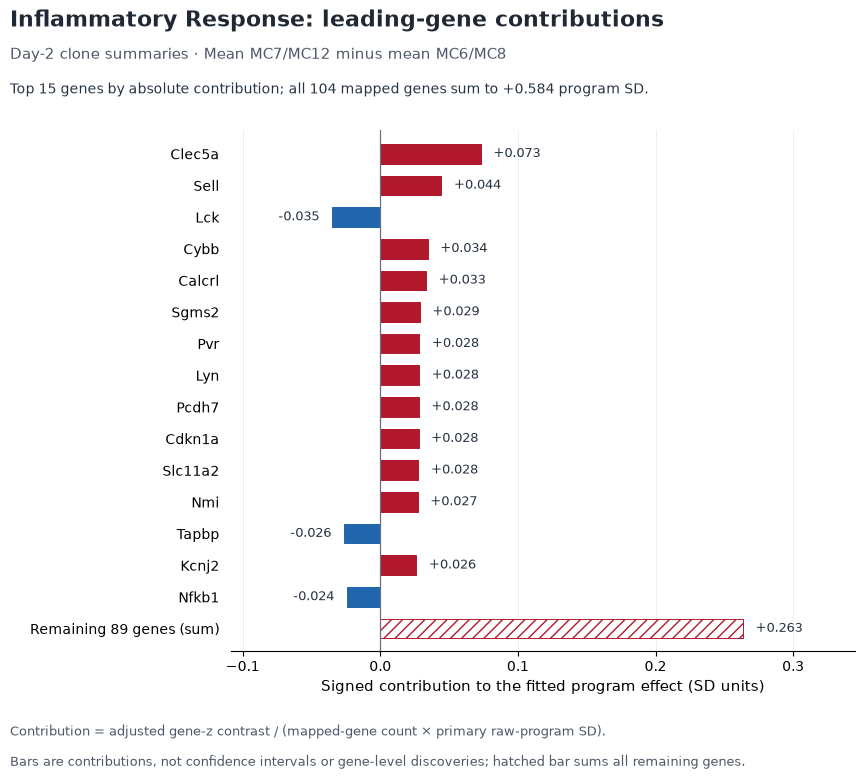

,display_label,program_sd_contribution,n_genes_represented
0,Clec5a,0.072988,1
1,Sell,0.044328,1
2,Lck,-0.035072,1
3,Cybb,0.034374,1
4,Calcrl,0.033194,1
5,Sgms2,0.028647,1
6,Pvr,0.028292,1
7,Lyn,0.028191,1
8,Pcdh7,0.027957,1
9,Cdkn1a,0.027794,1


/path/to/ChronoClone/analysis_workspace/analyses/weinreb_metaclone_ancestry_worked_examples_20260910/figures/program_08_mono_1_leading_gene_contributions.svg


In [20]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: exact additive program-effect decomposition, top genes by
# absolute contribution plus the signed sum of all remaining mapped genes.
example_id = 'mono_1'
plot_stem = 'program_08_mono_1_leading_gene_contributions'
example = selection.loc[selection.example_id == example_id].iloc[0]
gene_data = gene_contributions[gene_contributions.example_id == example_id].copy().sort_values('rank_abs_contribution')
n_show = min(15, len(gene_data))
shown = gene_data.head(n_show).copy()
shown['display_label'] = shown.gene
shown['display_role'] = 'individual gene'
shown['n_genes_represented'] = 1
if len(gene_data) > n_show:
    rest = gene_data.iloc[n_show:]
    other = {c: np.nan for c in shown.columns}
    other.update({'example_id': example_id, 'program': str(example.program), 'contrast_id': str(example.contrast_id),
                  'gene': '|'.join(rest.gene.astype(str)), 'rank_abs_contribution': n_show + 1,
                  'program_sd_contribution': float(rest.program_sd_contribution.sum()),
                  'program_effect_sd': float(example.effect_sd), 'program_mapped_genes': len(gene_data),
                  'selection': 'signed sum of all unshown mapped genes',
                  'display_label': f'Remaining {len(rest)} genes (sum)', 'display_role': 'remaining gene aggregate',
                  'n_genes_represented': len(rest)})
    shown = pd.concat([shown, pd.DataFrame([other])], ignore_index=True)
plot_data = shown.reset_index(drop=True)
plot_data['display_order'] = np.arange(len(plot_data))
plot_data['contrast_label'] = str(example.contrast_label)
plot_data['statistical_test'] = 'none; additive decomposition of fitted program effect'
assert np.isclose(plot_data.program_sd_contribution.sum(), float(example.effect_sd), atol=1e-9)
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)

fig, ax = plt.subplots(figsize=(10.5, 8.2))
fig.subplots_adjust(left=0.285, right=0.88, bottom=0.18, top=0.815)
values = plot_data.program_sd_contribution.to_numpy(float)
colors = ['#B2182B' if x >= 0 else '#2166AC' for x in values]
bars = ax.barh(plot_data.display_order, values, height=0.62, color=colors, edgecolor=colors, linewidth=0.7)
for bar, role in zip(bars, plot_data.display_role):
    if role == 'remaining gene aggregate': bar.set_facecolor('white'); bar.set_hatch('///')
ax.axvline(0, color='#667283', linewidth=0.9)
span = max(float(np.max(np.abs(values))), 0.01)
ax.set_xlim(min(float(values.min()), 0) - 0.28 * span, max(float(values.max()), 0) + 0.31 * span)
for r in plot_data.itertuples(index=False):
    sign = 1 if r.program_sd_contribution >= 0 else -1
    ax.text(r.program_sd_contribution + sign * 0.035 * span, r.display_order,
            f'{r.program_sd_contribution:+.3f}', ha='left' if sign > 0 else 'right',
            va='center', fontsize=9.2, color='#283444')
ax.set_yticks(plot_data.display_order, plot_data.display_label, fontsize=10.1)
ax.set_ylim(len(plot_data) - 0.3, -0.75)
ax.set_xlabel('Signed contribution to the fitted program effect (SD units)', fontsize=10.5)
ax.tick_params(axis='y', length=0, pad=8)
ax.spines['left'].set_visible(False)
ax.grid(axis='x', color='#EBEEF2', linewidth=0.65)
ax.set_axisbelow(True)
title = str(example.program).replace('HALLMARK_', '').replace('_', ' ')
fig.text(0.075, 0.962, title + ': leading-gene contributions', ha='left', va='top',
         fontsize=16, weight='bold', color='#202833')
fig.text(0.075, 0.916, f'Day-2 clone summaries · {example.contrast_label}', ha='left', va='top', fontsize=11, color='#4D5868')
fig.text(0.075, 0.873, f'Top {n_show} genes by absolute contribution; all {len(gene_data)} mapped genes sum to {example.effect_sd:+.3f} program SD.',
         ha='left', va='top', fontsize=10.3, color='#283444')
fig.text(0.075, 0.090, 'Contribution = adjusted gene-z contrast / (mapped-gene count × primary raw-program SD).',
         ha='left', va='top', fontsize=9.5, color='#4D5868')
fig.text(0.075, 0.053, 'Bars are contributions, not confidence intervals or gene-level discoveries; hatched bar sums all remaining genes.',
         ha='left', va='top', fontsize=9.5, color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(plot_data[['display_label', 'program_sd_contribution', 'n_genes_represented']])
print(FIGDIR / f'{plot_stem}.svg')
plot_runtime_audit.append({'notebook_cell_index':31,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


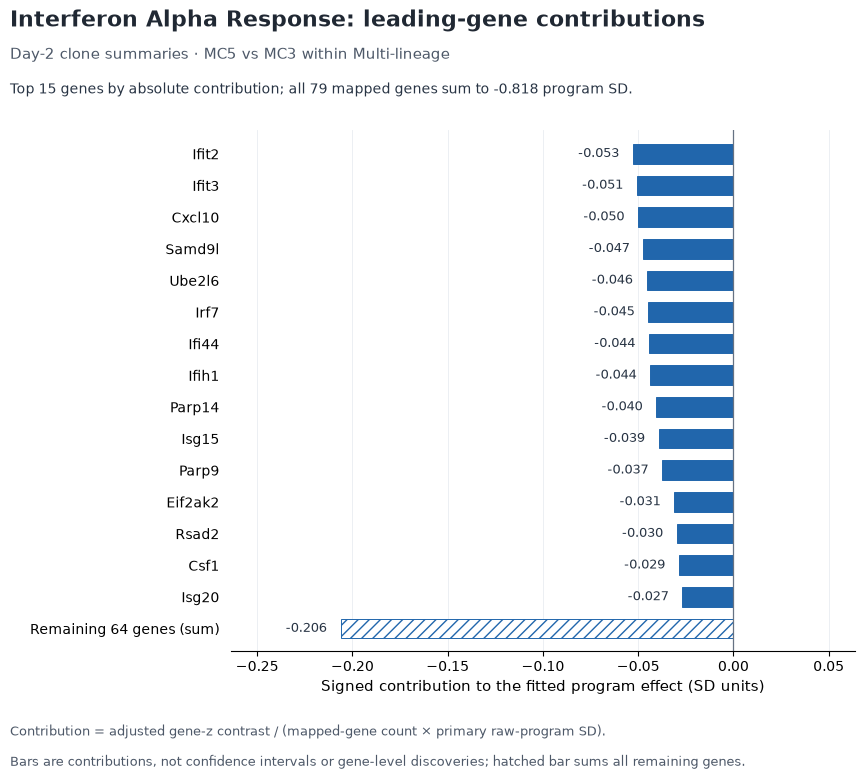

,display_label,program_sd_contribution,n_genes_represented
0,Ifit2,-0.052770,1
1,Ifit3,-0.050689,1
2,Cxcl10,-0.050040,1
3,Samd9l,-0.047215,1
4,Ube2l6,-0.045628,1
5,Irf7,-0.044636,1
6,Ifi44,-0.044333,1
7,Ifih1,-0.043621,1
8,Parp14,-0.040476,1
9,Isg15,-0.039266,1


/path/to/ChronoClone/analysis_workspace/analyses/weinreb_metaclone_ancestry_worked_examples_20260910/figures/program_09_multi_divergence_leading_gene_contributions.svg


In [21]:
_figure_count_before=len(figure_creation_log); _svg_count_before=len(svg_save_log)
# Chart contract: exact additive program-effect decomposition, top genes by
# absolute contribution plus the signed sum of all remaining mapped genes.
example_id = 'multi_divergence'
plot_stem = 'program_09_multi_divergence_leading_gene_contributions'
example = selection.loc[selection.example_id == example_id].iloc[0]
gene_data = gene_contributions[gene_contributions.example_id == example_id].copy().sort_values('rank_abs_contribution')
n_show = min(15, len(gene_data))
shown = gene_data.head(n_show).copy()
shown['display_label'] = shown.gene
shown['display_role'] = 'individual gene'
shown['n_genes_represented'] = 1
if len(gene_data) > n_show:
    rest = gene_data.iloc[n_show:]
    other = {c: np.nan for c in shown.columns}
    other.update({'example_id': example_id, 'program': str(example.program), 'contrast_id': str(example.contrast_id),
                  'gene': '|'.join(rest.gene.astype(str)), 'rank_abs_contribution': n_show + 1,
                  'program_sd_contribution': float(rest.program_sd_contribution.sum()),
                  'program_effect_sd': float(example.effect_sd), 'program_mapped_genes': len(gene_data),
                  'selection': 'signed sum of all unshown mapped genes',
                  'display_label': f'Remaining {len(rest)} genes (sum)', 'display_role': 'remaining gene aggregate',
                  'n_genes_represented': len(rest)})
    shown = pd.concat([shown, pd.DataFrame([other])], ignore_index=True)
plot_data = shown.reset_index(drop=True)
plot_data['display_order'] = np.arange(len(plot_data))
plot_data['contrast_label'] = str(example.contrast_label)
plot_data['statistical_test'] = 'none; additive decomposition of fitted program effect'
assert np.isclose(plot_data.program_sd_contribution.sum(), float(example.effect_sd), atol=1e-9)
plot_data.to_csv(TABLEDIR / f'{plot_stem}_plot_data.csv', index=False)

fig, ax = plt.subplots(figsize=(10.5, 8.2))
fig.subplots_adjust(left=0.285, right=0.88, bottom=0.18, top=0.815)
values = plot_data.program_sd_contribution.to_numpy(float)
colors = ['#B2182B' if x >= 0 else '#2166AC' for x in values]
bars = ax.barh(plot_data.display_order, values, height=0.62, color=colors, edgecolor=colors, linewidth=0.7)
for bar, role in zip(bars, plot_data.display_role):
    if role == 'remaining gene aggregate': bar.set_facecolor('white'); bar.set_hatch('///')
ax.axvline(0, color='#667283', linewidth=0.9)
span = max(float(np.max(np.abs(values))), 0.01)
ax.set_xlim(min(float(values.min()), 0) - 0.28 * span, max(float(values.max()), 0) + 0.31 * span)
for r in plot_data.itertuples(index=False):
    sign = 1 if r.program_sd_contribution >= 0 else -1
    ax.text(r.program_sd_contribution + sign * 0.035 * span, r.display_order,
            f'{r.program_sd_contribution:+.3f}', ha='left' if sign > 0 else 'right',
            va='center', fontsize=9.2, color='#283444')
ax.set_yticks(plot_data.display_order, plot_data.display_label, fontsize=10.1)
ax.set_ylim(len(plot_data) - 0.3, -0.75)
ax.set_xlabel('Signed contribution to the fitted program effect (SD units)', fontsize=10.5)
ax.tick_params(axis='y', length=0, pad=8)
ax.spines['left'].set_visible(False)
ax.grid(axis='x', color='#EBEEF2', linewidth=0.65)
ax.set_axisbelow(True)
title = str(example.program).replace('HALLMARK_', '').replace('_', ' ')
fig.text(0.075, 0.962, title + ': leading-gene contributions', ha='left', va='top',
         fontsize=16, weight='bold', color='#202833')
fig.text(0.075, 0.916, f'Day-2 clone summaries · {example.contrast_label}', ha='left', va='top', fontsize=11, color='#4D5868')
fig.text(0.075, 0.873, f'Top {n_show} genes by absolute contribution; all {len(gene_data)} mapped genes sum to {example.effect_sd:+.3f} program SD.',
         ha='left', va='top', fontsize=10.3, color='#283444')
fig.text(0.075, 0.090, 'Contribution = adjusted gene-z contrast / (mapped-gene count × primary raw-program SD).',
         ha='left', va='top', fontsize=9.5, color='#4D5868')
fig.text(0.075, 0.053, 'Bars are contributions, not confidence intervals or gene-level discoveries; hatched bar sums all remaining genes.',
         ha='left', va='top', fontsize=9.5, color='#4D5868')
fig.savefig(FIGDIR / f'{plot_stem}.svg', bbox_inches='tight')
fig.savefig(FIGDIR / f'{plot_stem}.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
display(plot_data[['display_label', 'program_sd_contribution', 'n_genes_represented']])
print(FIGDIR / f'{plot_stem}.svg')
plot_runtime_audit.append({'notebook_cell_index':32,'figures_created':len(figure_creation_log)-_figure_count_before,'svg_saves':len(svg_save_log)-_svg_count_before,'svg_stems':'|'.join(svg_save_log[_svg_count_before:])})
assert plot_runtime_audit[-1]['figures_created']==1 and plot_runtime_audit[-1]['svg_saves']==1


## Computed findings and checks
The report below is generated from the complete effect, sensitivity, and
selected-example tables. Statistical support and descriptive illustration
are reported separately. cNMF findings are carried forward without refitting
or changing the declared recovery gates.

In [22]:
findings=[]
findings.append('WEINREB METACLONE ANCESTRY WORKED EXAMPLES')
findings.append(f'Assigned Day2 HSPCs: {len(hspc_cells)} cells from {len(metadata)} LARRY clones; all analyses use clone summaries.')
findings.append(f'Original score/effect reconstruction max errors: {score_error:.3g} / {effect_error:.3g}.')
findings.append(f'Ratio normalization uses {baseline["normalization_genes"]} universally positive genes, including {sum(g.lower().startswith("mt-") for g in baseline["normalization_gene_names"].split("|"))} mitochondrial genes. A nonmitochondrial positive-count sensitivity uses {nonmito["normalization_genes"]} eligible genes; original integer recovery remains an assumption. Exact reproduction does not independently validate it.')
pace_results=primary[primary.contrast_id=='Monocyte_fast_minus_slow']
findings.append(f'New equal-MC monocyte pace comparison: {(pace_results.qvalue<.05).sum()}/50 programs at BH q<0.05; {((pace_results.qvalue>=.05)&(pace_results.qvalue<.10)).sum()}/50 additional at exploratory 0.05<=q<0.10.')
for row in selection.itertuples(index=False):
    findings.append(f'{row.example_id} normalization sensitivity: nonmitochondrial positive-count effect {row.nonmito_effect_primary_scale:+.4f} in frozen primary units, refit-native effect {row.nonmito_effect_native_sd:+.4f} SD with native BH q={row.nonmito_native_qvalue:.5g}; direction agrees={row.nonmito_same_direction}.')
    findings.append(f'{row.example_id}: {row.program}; {row.contrast_label}; effect {row.effect_sd:+.4f} SD, pointwise 95% CI [{row.ci_low:+.4f}, {row.ci_high:+.4f}], q={row.qvalue:.5g}; {row.evidence_tier}; supported LOO directions {row.loo_same_direction}/{row.loo_supported} of {row.loo_expected} expected; source-fraction effect {row.source_fraction_effect_sd:+.4f}; prog2-only supported={row.prog2_supported}, fixed-scale effect={row.prog2_effect_primary_scale:+.4f}.')
findings.append('DYNAMICS AND SUPPORT: the branch masks overlap and do not constitute a complete, mutually exclusive terminal-output vector.')
for row in dyn_pair_distances[dyn_pair_distances.estimator.eq('clone_balanced_occupancy')].itertuples(index=False):
    findings.append(f'{row.cohort}: MC{row.metaclone_a}–MC{row.metaclone_b} three-branch occupancy distance {row.day4_distance:.4f} at Day4 to {row.day6_distance:.4f} at Day6 ({row.observed_direction}).')
for row in dyn_state_pair_distances[dyn_state_pair_distances.cohort.eq('day2_hspc_linked')].itertuples(index=False):
    findings.append(f'Complete {row.annotation} state composition: MC{row.metaclone_a}–MC{row.metaclone_b} distance {row.day4_distance:.4f} to {row.day6_distance:.4f}; this is a different coordinate system from branch occupancy.')
findings += ['Illustration selection uses observed effect sizes, not significance or sensitivity results. Complete rankings are saved.',
 'Original q values and families remain unchanged. The exploratory tier is a post hoc display annotation, not confirmatory evidence.',
 'Zero discoveries are not equivalence. Same-direction pairs are not proof of a universal/shared program.',
 'Library-removal and source-restricted analyses change observed cells; loss of support is NE, not a negative result.',
 'Pooled and metaclone-resolved distribution plots repeat the same clones; no test treats these repeated views as independent groups.',
 'Day2 cells are sampled clonal relatives. The behavior-to-program comparison is retrospective and conditional on an in-sample metaclone partition.',
 'cNMF remains a secondary readout; its original complete library-recovery gate and novelty assessment are preserved. No inference is drawn from heatmap color alone.']
cnmf_report=(SOURCE_DIR/'reports/cnmf_findings_and_boundaries.txt').read_text()
(REPORTDIR/'computed_findings.txt').write_text('\n'.join(findings)+'\n\nPRESERVED cNMF RESULT\n'+cnmf_report)
print('\n'.join(findings))

checks=[]
def check(name,passed,detail):
    checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})
check('one_primary_observation_per_clone',metadata.index.is_unique,len(metadata))
check('all_source_scores_reproduced',score_error<1e-8,score_error)
check('all_original_within_family_effects_reproduced',effect_error<1e-8,effect_error)
check('all_original_within_family_pvalues_reproduced',p_error<1e-8,p_error)
check('fixed_50_programs',len(PROGRAMS)==50,len(PROGRAMS))
check('fixed_original_gene_universe',len(GENES)==9777,len(GENES))
check('full_original_OVR_family',len(primary[primary.tier=='within_lineage_ovr'])==950,950)
check('full_original_pair_family',len(primary[primary.tier=='within_lineage_pairwise'])==2000,2000)
check('new_pace_family_declared_50',len(pace_results)==50,len(pace_results))
check('all_sensitivity_variants_present',sensitivity.variant.nunique()==len(libraries)+3,sensitivity.variant.unique())
check('no_population_variable','population' not in metadata and 'population' not in obs,True)
check('all_primary_effects_finite',np.isfinite(primary.effect_sd).all(),len(primary))
check('example_selection_independent_of_q_threshold',len(selection)==4,len(selection))
check('gene_contribution_sums_match_program_effects',all(np.isclose(g.program_sd_contribution.sum(),g.program_effect_sd.iloc[0],atol=1e-9) for _,g in gene_contributions.groupby('example_id')),len(selection))
check('source_manifest_hashes_unchanged',all(sha256(PROJECT_ROOT/r.path)==r.sha256 for r in source_manifest.itertuples(index=False)),len(source_manifest))
svgs=sorted(FIGDIR.glob('*.svg'))
check('all_figures_have_png_companions',all(p.with_suffix('.png').exists() for p in svgs),len(svgs))
check('all_svgs_editable_no_raster',all('<image' not in p.read_text() for p in svgs),len(svgs))
check('twelve_independent_figures',len(svgs)==12,len(svgs))
runtime_audit=pd.DataFrame(plot_runtime_audit)
runtime_audit.to_csv(REPORTDIR/'plot_runtime_audit.csv',index=False)
check('one_figure_and_svg_per_plot_cell',len(runtime_audit)==12 and runtime_audit.figures_created.eq(1).all() and runtime_audit.svg_saves.eq(1).all(),len(runtime_audit))
for name,passed in dyn_checks.items(): check('dynamics_'+name,passed,passed)
check('all_sensitivity_family_sizes_preserved',sensitivity.groupby(['variant','tier']).size().eq(sensitivity.groupby(['variant','tier']).size().index.get_level_values('tier').map({'within_lineage_ovr':950,'within_lineage_pairwise':2000,'monocyte_pace_50':50})).all(),len(sensitivity))
check('nonmitochondrial_normalization_omits_mitochondrial_genes',not any(g.lower().startswith('mt-') for g in nonmito['normalization_gene_names'].split('|')),nonmito['normalization_genes'])
validation=pd.DataFrame(checks);validation.to_csv(REPORTDIR/'validation.csv',index=False)
display(validation)
assert validation.passed.all()
artifacts=[]
for directory in [FIGDIR,TABLEDIR,REPORTDIR,PROVDIR]:
    for p in sorted(directory.rglob('*')):
        if p.is_file() and p.name!='artifact_manifest.csv' and not p.name.startswith(('evidence_review_','manuscript_')):
            artifacts.append({'path':str(p.relative_to(PROJECT_ROOT)),'bytes':p.stat().st_size,'sha256':sha256(p)})
pd.DataFrame(artifacts).to_csv(REPORTDIR/'artifact_manifest.csv',index=False)
print(f'{validation.passed.sum()}/{len(validation)} checks pass; {len(svgs)} editable SVGs; {len(artifacts)} registered outputs.')

WEINREB METACLONE ANCESTRY WORKED EXAMPLES
Assigned Day2 HSPCs: 775 cells from 569 LARRY clones; all analyses use clone summaries.
Original score/effect reconstruction max errors: 3.11e-15 / 6.61e-15.
Ratio normalization uses 9 universally positive genes, including 5 mitochondrial genes. A nonmitochondrial positive-count sensitivity uses 9053 eligible genes; original integer recovery remains an assumption. Exact reproduction does not independently validate it.
New equal-MC monocyte pace comparison: 30/50 programs at BH q<0.05; 1/50 additional at exploratory 0.05<=q<0.10.
mono_1 normalization sensitivity: nonmitochondrial positive-count effect +1.5094 in frozen primary units, refit-native effect +0.7255 SD with native BH q=1.815e-05; direction agrees=True.
mono_1: Inflammatory Response; Mean MC7/MC12 minus mean MC6/MC8; effect +0.5844 SD, pointwise 95% CI [+0.2583, +0.9105], q=0.002291; FDR_lt_0.05; supported LOO directions 7/7 of 7 expected; source-fraction effect +0.5918; prog2-only s

,check,passed,detail
0,one_primary_observation_per_clone,True,569
1,all_source_scores_reproduced,True,3.1086244689504383e-15
2,all_original_within_family_effects_reproduced,True,6.6058269965196814e-15
3,all_original_within_family_pvalues_reproduced,True,1.9095836023552692e-14
4,fixed_50_programs,True,50
5,fixed_original_gene_universe,True,9777
6,full_original_OVR_family,True,950
7,full_original_pair_family,True,2000
8,new_pace_family_declared_50,True,50
9,all_sensitivity_variants_present,True,['source_fraction_adjusted' 'without_library__...


32/32 checks pass; 12 editable SVGs; 82 registered outputs.
